# CV3D Pipeline: Multi-Object Reconstruction, Masking & Nerfstudio Benchmark
**Project:** From Photos to 3D: NeRF and Gaussian Splatting in Practice  
**Authors:** TBN & Team  
**Runtime:** Google Colab (T4 / L4 / A100 GPU) — Hỗ trợ chạy trực tiếp trong Antigravity IDE hoặc trình duyệt Colab

Notebook này thực thi toàn bộ pipeline 3D Reconstruction trên ổ đĩa NVMe `/content/` tốc độ cao của Colab, kết hợp **cơ chế tự động lưu Checkpoint & tự động chạy tiếp (Auto-Resume) trên Google Drive** để đảm bảo nếu Colab bị ngắt GPU giữa chừng thì **không bao giờ phải chạy lại từ đầu**.

### Curated Objects (Trong thư mục `99_archives`)
- `box_001`: Techcombank Gift Box (321 frames, SAM 2 dilated stool-subtraction masks)
- `basket_001`: Bamboo & Mesh Fruit Basket (362 frames, SAM 2 video predictor temporal masks)
- `figure_001`: Anime PVC Figurine (362 frames, clean draft masks)
- `stuff_toy_001`: Cotton Stuffed Horse (337 frames, SAM 2 video predictor temporal masks)

### Cơ chế chống mất dữ liệu khi Colab ngắt kết nối (Crash Recovery)
1. **Tự động lưu & khôi phục COLMAP (`joint_sfm`)**: Ngay khi chạy xong bước 7 (COLMAP + Gắn Mask + Chia Split), kết quả được nén và lưu ngay lên Google Drive (`05_processed/processed_<OBJECT_ID>_joint_sfm_v001.tar`). Ở các lần chạy sau, Cell 2 sẽ tự động phát hiện bản lưu này, giải nén trong 5 giây và **tự động bỏ qua bước chạy lại COLMAP (tiết kiệm 20–30 phút)**.
2. **Lưu Checkpoint mỗi 2,000 vòng lặp & Auto-Resume (`--load-dir`)**: Trong bước 9, mọi checkpoint huấn luyện (`nerfacto`, `splatfacto`) được lưu trực tiếp lên Google Drive (`06_experiments/<OBJECT_ID>`). Nếu Colab ngắt ở vòng 16,000/30,000, khi chạy lại Cell 9, script tự động tìm checkpoint mới nhất và **train tiếp từ vòng 16,000**.
3. **Tự động bỏ qua (Skip) các bài đã train xong**: Bài thí nghiệm nào đã có file điểm `metrics_*.json` trên Drive sẽ được bỏ qua ngay lập tức và cập nhật thẳng vào bảng tổng hợp `results.csv`.

In [1]:
#@title ⚙️ Cấu hình Pipeline & Chọn Vật thể (Pipeline Configuration)
#@markdown Chọn vật thể (`OBJECT_ID`) và chế độ chạy (`SMOKE_TEST_ONLY = False` để chạy huấn luyện thật 30,000 vòng ở Cell 9).

OBJECT_ID = "box_001" #@param ["box_001", "basket_001", "figure_001", "stuff_toy_001"]
DRIVE_PROJECT_FOLDER = "CV3D_Final_Project" #@param {type:"string"}
SHARED_ARCHIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1Dei_NHsdo2pQcnjJ5fyD6C771sRSigPD" #@param {type:"string"}
DOWNSCALE_FACTOR = 2 #@param [1, 2, 4]
SFM_MATCHING_METHOD = "vocab_tree" #@param ["vocab_tree", "exhaustive"]
SMOKE_TEST_ONLY = False #@param {type:"boolean"}
FULL_TRAIN_ITERS = 30000 #@param {type:"integer"}
STEPS_PER_SAVE = 2000 #@param {type:"integer"}
FORCE_RERUN_SFM = False #@param {type:"boolean"}

print(f"🎯 Target Object          : {OBJECT_ID}")
print(f"📁 Google Drive Base      : MyDrive/{DRIVE_PROJECT_FOLDER}")
print(f"🔍 COLMAP Matching Method : {SFM_MATCHING_METHOD}")
print(f"🖼️ Image Downscale Factor : {DOWNSCALE_FACTOR}")
print(f"💾 Checkpoint Save Every  : {STEPS_PER_SAVE} steps")
print(f"🚀 Training Mode          : {'Smoke Test (500 iters)' if SMOKE_TEST_ONLY else f'Full Training ({FULL_TRAIN_ITERS} iters)'}")

🎯 Target Object          : box_001
📁 Google Drive Base      : MyDrive/CV3D_Final_Project
🔍 COLMAP Matching Method : vocab_tree
🖼️ Image Downscale Factor : 2
💾 Checkpoint Save Every  : 2000 steps
🚀 Training Mode          : Full Training (30000 iters)


In [ ]:
#@title 🔌 0. KIỂM TRA NHANH KẾT NỐI COLAB GPU & GOOGLE DRIVE (Chạy thử trong 5 giây)
#@markdown Chạy cell này đầu tiên để xác nhận:
#@markdown 1. Máy chủ Google Colab đã cấp phát GPU thành công.
#@markdown 2. Tài khoản Google Drive đã được mount và có quyền đọc/ghi để lưu checkpoint.
#@markdown 3. Kiểm tra xem đã thấy file data `dataset_<OBJECT_ID>.tar` (hoặc bản backup COLMAP) trên Drive chưa.

import subprocess, time
from pathlib import Path
import torch

print("=== 1. KIỂM TRA GPU TRÊN COLAB ===")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"✅ Đã kết nối GPU thành công: {gpu_name} ({vram_gb:.1f} GB VRAM)")
else:
    print("❌ CẢNH BÁO: Chưa tìm thấy GPU! Hãy chọn Kernel Colab có GPU (T4/L4/A100).")

print("\n=== 2. KIỂM TRA KẾT NỐI & QUYỀN GHI GOOGLE DRIVE ===")
from google.colab import drive
drive.mount('/content/drive')

DRIVE = Path(f'/content/drive/MyDrive/{DRIVE_PROJECT_FOLDER}')
for sub in ['00_documentation/manifests', '05_processed', f'06_experiments/{OBJECT_ID}', f'07_final_results/{OBJECT_ID}']:
    (DRIVE / sub).mkdir(parents=True, exist_ok=True)

# Ghi thử 1 file nhỏ để đảm bảo Drive có quyền ghi (Write Permission)
test_file = DRIVE / 'connection_test.txt'
test_file.write_text(f'Connected successfully at {time.strftime("%Y-%m-%d %H:%M:%S")}\nObject: {OBJECT_ID}\n', encoding='utf-8')
print(f"✅ Đã mount và ghi thử file thành công vào: {test_file}")

print("\n=== 3. KIỂM TRA DỮ LIỆU ĐẦU VÀO & CHECKPOINT TRÊN DRIVE ===")
shortcut_archive = DRIVE / '99_archives' / f'dataset_{OBJECT_ID}.tar'
saved_sfm_archive = DRIVE / '05_processed' / f'processed_{OBJECT_ID}_joint_sfm_v001.tar'

if saved_sfm_archive.exists():
    print(f"🎉 PHÁT HIỆN BẢN LƯU COLMAP: {saved_sfm_archive} ({saved_sfm_archive.stat().st_size / (1024**3):.2f} GB)")
    print("   -> Khi chạy pipeline, hệ thống sẽ khôi phục ngay bản này và KHÔNG cần chạy lại COLMAP!")
elif shortcut_archive.exists():
    print(f"✅ Đã tìm thấy file dữ liệu gốc qua lối tắt Drive: {shortcut_archive} ({shortcut_archive.stat().st_size / (1024**3):.2f} GB)")
else:
    print(f"ℹ️ Chưa thấy lối tắt tại {shortcut_archive}.")
    print(f"   -> Không sao! Ở bước 2, nếu chưa có lối tắt, script sẽ tự động tải từ link {SHARED_ARCHIVE_FOLDER_URL} bằng gdown.")

In [2]:
#@title 🛠️ 1. Cài đặt môi trường COLMAP & Nerfstudio (Environment Preflight)
#@markdown Cài đặt COLMAP, FFmpeg, Nerfstudio và các thư viện phụ trợ trên máy ảo Colab (~3–5 phút).
!nvidia-smi
!apt-get update -qq
!apt-get install -y -qq colmap ffmpeg xvfb
!pip install -q --upgrade pip
!pip install -q nerfstudio rembg onnxruntime-gpu gdown
import os, subprocess, sys
os.environ['QT_QPA_PLATFORM'] = 'offscreen'
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'

# Vá tương thích PyTorch 2.6+ (weights_only=False) cho ns-eval và ns-train --load-dir.
# QUAN TRỌNG: chạy trong tiến trình Python MỚI (subprocess), KHÔNG import nerfstudio trong kernel,
# vì pip vừa nâng cấp numpy -> import trong kernel cũ gây lỗi '_blas_supports_fpe' (numpy cũ/mới lẫn lộn).
PATCH_CODE = '''
import importlib.util, pathlib
root = pathlib.Path(importlib.util.find_spec("nerfstudio").origin).parent
old = 'torch.load(load_path, map_location="cpu")'
new = 'torch.load(load_path, map_location="cpu", weights_only=False)'
for rel in ("utils/eval_utils.py", "engine/trainer.py"):
    p = root / rel
    t = p.read_text(encoding="utf-8")
    if old in t:
        p.write_text(t.replace(old, new), encoding="utf-8")
print("✅ Đã vá tương thích PyTorch 2.6+ cho Nerfstudio tại", root)
'''
open('/content/patch_nerfstudio_torch26.py', 'w', encoding='utf-8').write(PATCH_CODE)
subprocess.run([sys.executable, '/content/patch_nerfstudio_torch26.py'], check=False)

# Kiểm tra numpy trong kernel có khớp bản vừa cài không -> nếu lệch thì cần Restart Kernel 1 lần
import numpy as _np
_disk_np = subprocess.run([sys.executable, '-c', 'import numpy; print(numpy.__version__)'], capture_output=True, text=True).stdout.strip()
if _disk_np and _disk_np != _np.__version__:
    print(f'⚠️ numpy trong kernel ({_np.__version__}) khác bản vừa cài ({_disk_np}) -> hãy RESTART KERNEL 1 lần (thư viện đã cài vẫn giữ nguyên), rồi chạy Cell ⚙️ -> Cell 9.')
else:
    print(f'✅ numpy {_np.__version__} đồng bộ, không cần restart kernel.')
!ns-process-data --help | head -n 5
!ns-train --help | head -n 5

Tue Nov  3 01:08:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             44W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
#@title 📦 2. Chuẩn bị Dữ liệu, Khôi phục Script & Kiểm tra Bản lưu COLMAP (Smart Resume)
#@markdown **Cơ chế thông minh:**
#@markdown - Nếu trên Google Drive (`05_processed/`) **đã có** file `processed_<OBJECT_ID>_joint_sfm_v001.tar` từ lần chạy trước, cell này sẽ giải nén thẳng kết quả COLMAP + Mask + Splits ra `/content/` và đặt cờ `SFM_ALREADY_DONE = True` để tự động bỏ qua các bước 3, 4, 5, 6, 7.
#@markdown - Nếu **chưa có**, cell sẽ copy `dataset_<OBJECT_ID>.tar` từ lối tắt `99_archives` (hoặc tải tự động qua `gdown`) vào ổ NVMe `/content/` để chuẩn bị chạy COLMAP.

from google.colab import drive
from pathlib import Path
import shutil, os, cv2

# 1. Đảm bảo Google Drive đã được mount
if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

DRIVE = Path(f'/content/drive/MyDrive/{DRIVE_PROJECT_FOLDER}')
WORK = Path('/content/project')
WORK.mkdir(parents=True, exist_ok=True)

# Tạo sẵn các thư mục lưu trữ trên Google Drive
for sub in ['00_documentation/manifests', '05_processed', f'06_experiments/{OBJECT_ID}', f'07_final_results/{OBJECT_ID}']:
    (DRIVE / sub).mkdir(parents=True, exist_ok=True)

# 2. Khôi phục các script xử lý vào /content/project/scripts
scripts_dir = WORK / 'scripts'
scripts_dir.mkdir(parents=True, exist_ok=True)
embedded_scripts = {'audit_registration.py': '"""Report COLMAP/Nerfstudio image registration by capture-condition prefix.\n\nExample:\n  python scripts/audit_registration.py \\\n      --input-images data/colmap_input/images \\\n      --transforms data/processed/joint_sfm/transforms.json \\\n      --output-csv data/manifests/registration_by_condition.csv\n\nThe input directory is the complete submitted image set. transforms.json contains\nonly images registered by COLMAP, so this computes registered/submitted counts.\n"""\nfrom __future__ import annotations\nimport argparse\nimport csv\nfrom pathlib import Path\n\nEXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}\nDEFAULT_PREFIXES = ("orbit_", "spiral_", "blur_1_50_", "blur_1_25_", "holdout_")\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--input-images", type=Path, required=True)\n    parser.add_argument("--transforms", type=Path, required=True)\n    parser.add_argument("--output-csv", type=Path, required=True)\n    parser.add_argument("--prefixes", default=",".join(DEFAULT_PREFIXES))\n    args = parser.parse_args()\n\n    if not args.input_images.is_dir():\n        raise SystemExit(f"Input image directory not found: {args.input_images}")\n    if not args.transforms.is_file():\n        raise SystemExit(f"Transforms JSON not found: {args.transforms}")\n\n    import json\n    meta = json.loads(args.transforms.read_text(encoding="utf-8"))\n    submitted = sorted(p.name for p in args.input_images.iterdir()\n                       if p.is_file() and p.suffix.lower() in EXTS)\n    registered = {Path(frame["file_path"]).name for frame in meta.get("frames", [])}\n    prefixes = [x.strip() for x in args.prefixes.split(",") if x.strip()]\n    if not submitted:\n        raise SystemExit("No supported image files found in input directory")\n\n    rows = []\n    total_registered = 0\n    for prefix in prefixes:\n        group_submitted = [n for n in submitted if n.startswith(prefix)]\n        group_registered = [n for n in group_submitted if n in registered]\n        n_sub, n_reg = len(group_submitted), len(group_registered)\n        total_registered += n_reg\n        fraction = n_reg / n_sub if n_sub else 0.0\n        rows.append({"condition_prefix": prefix, "submitted": n_sub,\n                     "registered": n_reg, "registration_fraction": f"{fraction:.6f}"})\n\n    ungrouped = [n for n in submitted if not any(n.startswith(p) for p in prefixes)]\n    if ungrouped:\n        rows.append({"condition_prefix": "UNMATCHED", "submitted": len(ungrouped),\n                     "registered": sum(n in registered for n in ungrouped),\n                     "registration_fraction": f"{sum(n in registered for n in ungrouped)/len(ungrouped):.6f}"})\n\n    args.output_csv.parent.mkdir(parents=True, exist_ok=True)\n    with args.output_csv.open("w", newline="", encoding="utf-8") as f:\n        writer = csv.DictWriter(f, fieldnames=["condition_prefix", "submitted", "registered", "registration_fraction"])\n        writer.writeheader()\n        writer.writerows(rows)\n\n    total_submitted = len(submitted)\n    total_registered = len(registered.intersection(submitted))\n    overall = total_registered / total_submitted\n    print(f"Overall registration: {total_registered}/{total_submitted} = {overall:.1%}")\n    for row in rows:\n        print(f"{row[\'condition_prefix\']}: {row[\'registered\']}/{row[\'submitted\']} = {float(row[\'registration_fraction\']):.1%}")\n    print(f"Wrote {args.output_csv}")\n\n\nif __name__ == "__main__":\n    main()\n', 'attach_masks.py': '"""Attach masks to a Nerfstudio transforms.json by exact filename stem.\n\nCopies/resizes masks to masks/, masks_2/, masks_4/ matching existing image scales.\nFails on missing matches rather than silently pairing by sorted index.\n"""\nfrom __future__ import annotations\nimport argparse, json\nfrom pathlib import Path\nimport cv2\nimport numpy as np\n\ndef main() -> None:\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--dataset\',type=Path,required=True)\n    p.add_argument(\'--source-masks\',type=Path,required=True)\n    args=p.parse_args()\n    meta_path=args.dataset/\'transforms.json\'\n    if not meta_path.is_file(): raise SystemExit(f\'Missing {meta_path}\')\n    meta=json.loads(meta_path.read_text(encoding=\'utf-8\'))\n    frames=meta.get(\'frames\',[])\n    if not frames: raise SystemExit(\'transforms.json has no frames\')\n    masks={x.stem:x for x in args.source_masks.iterdir() if x.is_file() and x.suffix.lower()==\'.png\'}\n    missing=[]\n    for frame in frames:\n        image_rel=Path(frame[\'file_path\'])\n        image_path=args.dataset/image_rel\n        key=image_path.stem\n        if key not in masks: missing.append(key); continue\n        mask=cv2.imread(str(masks[key]),cv2.IMREAD_GRAYSCALE)\n        image=cv2.imread(str(image_path),cv2.IMREAD_COLOR)\n        if mask is None or image is None: raise SystemExit(f\'Unreadable image or mask for {key}\')\n        # Strict binary single-channel mask; black=ignore, white=keep.\n        mask=np.where(mask>=128,255,0).astype(np.uint8)\n        for scale,suffix in [(1,\'\'),(2,\'_2\'),(4,\'_4\')]:\n            image_dir=args.dataset/f\'images{suffix}\'\n            if not image_dir.is_dir(): continue\n            scaled_image=image if scale==1 else cv2.imread(str(image_dir/image_rel.name),cv2.IMREAD_COLOR)\n            if scaled_image is None: raise SystemExit(f\'Missing scaled image: {image_dir/image_rel.name}\')\n            h,w=scaled_image.shape[:2]\n            resized=cv2.resize(mask,(w,h),interpolation=cv2.INTER_NEAREST)\n            out_dir=args.dataset/f\'masks{suffix}\'; out_dir.mkdir(parents=True,exist_ok=True)\n            cv2.imwrite(str(out_dir/(image_rel.stem+\'.png\')),resized)\n        frame[\'mask_path\']=f\'masks/{image_rel.stem}.png\'\n    if missing:\n        raise SystemExit(\'No mask found for these image stems (no changes written): \'+\', \'.join(missing[:20]))\n    meta_path.write_text(json.dumps(meta,indent=2),encoding=\'utf-8\')\n    print(f\'Attached {len(frames)} masks by exact image stem.\')\n\nif __name__==\'__main__\': main()\n', 'create_condition_splits.py': '"""Create trajectory/blur and view-count splits with shared held-out cameras.\n\nInput must be one joint COLMAP/Nerfstudio reconstruction containing all image\nconditions. Prefixes are the filename stems used in the merged COLMAP input, e.g.\n  orbit_00001.png, spiral_00001.png, blur_1_50_00001.png, holdout_00001.png\n\nThe holdout prefix is split once into fixed validation/test sets. Each condition\ngets nested train subsets at requested ratios while using those same val/test\nimages and the same COLMAP coordinate system.\n"""\nfrom __future__ import annotations\nimport argparse, copy, json\nfrom pathlib import Path\nimport numpy as np\n\ndef fps(points: np.ndarray, count: int) -> list[int]:\n    if count<=0:return []\n    if count>=len(points):return list(range(len(points)))\n    first=int(np.argmax(np.sum((points-points.mean(axis=0))**2,axis=1)))\n    chosen=[first]; min_d=np.sum((points-points[first])**2,axis=1)\n    while len(chosen)<count:\n        j=int(np.argmax(min_d)); chosen.append(j)\n        min_d=np.minimum(min_d,np.sum((points-points[j])**2,axis=1))\n    return chosen\n\ndef main()->None:\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--dataset\',type=Path,required=True)\n    p.add_argument(\'--condition-prefix\',required=True,help=\'Filename stem prefix, e.g. orbit_\')\n    p.add_argument(\'--holdout-prefix\',default=\'holdout_\')\n    p.add_argument(\'--val-fraction\',type=float,default=0.35,help=\'Fraction of holdout pool reserved for validation; remainder is test.\')\n    p.add_argument(\'--ratios\',default=\'1.0,0.5,0.25,0.10\')\n    a=p.parse_args()\n    base=a.dataset/\'transforms.json\'; meta=json.loads(base.read_text(encoding=\'utf-8\'))\n    frames=meta.get(\'frames\',[])\n    if not frames:raise SystemExit(\'No frames in transforms.json\')\n    names=[]; poses=[]\n    for f in frames:\n        path=Path(f[\'file_path\']); names.append(f[\'file_path\']); poses.append(np.asarray(f[\'transform_matrix\'],dtype=float)[:3,3])\n    names_arr=np.asarray(names,dtype=object); poses_arr=np.asarray(poses)\n    hold=[i for i,n in enumerate(names) if Path(n).name.startswith(a.holdout_prefix)]\n    train=[i for i,n in enumerate(names) if Path(n).name.startswith(a.condition_prefix)]\n    if len(hold)<8:raise SystemExit(f\'Need >=8 registered holdout frames with prefix {a.holdout_prefix}; found {len(hold)}\')\n    if len(train)<10:raise SystemExit(f\'Need >=10 registered training frames with prefix {a.condition_prefix}; found {len(train)}\')\n    if not (0<a.val_fraction<0.8):raise SystemExit(\'--val-fraction must be between 0 and 0.8\')\n    test_n=max(2,min(len(hold)-2,round(len(hold)*(1.0-a.val_fraction))))\n    test_local=fps(poses_arr[hold],test_n); test=[hold[j] for j in test_local]\n    val_pool=[i for i in hold if i not in set(test)]\n    val_local=fps(poses_arr[val_pool],len(val_pool)); val=[val_pool[j] for j in val_local]\n    for r in [float(x) for x in a.ratios.split(\',\')]:\n        if not 0<r<=1:raise SystemExit(f\'Invalid ratio {r}\')\n        n=max(2,round(len(train)*r)); local=fps(poses_arr[train],min(n,len(train))); chosen=[train[j] for j in local]\n        out=copy.deepcopy(meta)\n        out[\'train_filenames\']=[names[i] for i in chosen]\n        out[\'val_filenames\']=[names[i] for i in val]\n        out[\'test_filenames\']=[names[i] for i in test]\n        out[\'split_protocol\']={\'condition_prefix\':a.condition_prefix,\'holdout_prefix\':a.holdout_prefix,\n          \'train_ratio\':r,\'train_count\':len(chosen),\'val_count\':len(val),\'test_count\':len(test),\n          \'shared_eval_cameras\':True,\'selection\':\'deterministic farthest-point sampling over COLMAP camera centres\'}\n        out_path=a.dataset/f\'transforms_{a.condition_prefix.rstrip("_")}_views_{int(round(r*100)):03d}.json\'\n        out_path.write_text(json.dumps(out,indent=2),encoding=\'utf-8\')\n        print(f\'{out_path.name}: train={len(chosen)}, val={len(val)}, test={len(test)}\')\n    print(\'Inspect the held-out views. This script uses camera-centre diversity, not a guarantee of perfect angular coverage.\')\n\nif __name__==\'__main__\':main()\n', 'validate_dataset.py': '"""Validate a Nerfstudio dataset JSON, image/mask paths, dimensions and splits."""\nfrom __future__ import annotations\nimport argparse, json\nfrom pathlib import Path\nimport cv2\nimport numpy as np\n\ndef main() -> None:\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--dataset\',type=Path,required=True)\n    p.add_argument(\'--transforms\',default=\'transforms.json\')\n    p.add_argument(\'--require-masks\',action=\'store_true\')\n    args=p.parse_args()\n    meta_path=args.dataset/args.transforms\n    if not meta_path.is_file(): raise SystemExit(f\'Missing metadata: {meta_path}\')\n    meta=json.loads(meta_path.read_text(encoding=\'utf-8\'))\n    frames=meta.get(\'frames\',[])\n    errors=[]; warnings=[]\n    if not frames: errors.append(\'No frames in transforms JSON.\')\n    image_paths=[]; mask_count=0; fg_fracs=[]\n    for i,fr in enumerate(frames):\n        if \'file_path\' not in fr or \'transform_matrix\' not in fr:\n            errors.append(f\'Frame {i} lacks file_path or transform_matrix.\'); continue\n        image_path=args.dataset/fr[\'file_path\']\n        image=cv2.imread(str(image_path),cv2.IMREAD_COLOR)\n        if image is None:\n            errors.append(f\'Image missing/unreadable: {image_path}\'); continue\n        image_paths.append(fr[\'file_path\'])\n        mat=np.asarray(fr[\'transform_matrix\'],dtype=np.float64)\n        if mat.shape!=(4,4) or not np.isfinite(mat).all(): errors.append(f\'Invalid 4x4 pose: {fr["file_path"]}\')\n        if \'w\' in meta and int(meta[\'w\'])!=image.shape[1]: warnings.append(f\'Image width differs from top-level metadata: {fr["file_path"]}\')\n        if \'h\' in meta and int(meta[\'h\'])!=image.shape[0]: warnings.append(f\'Image height differs from top-level metadata: {fr["file_path"]}\')\n        mp=fr.get(\'mask_path\')\n        if args.require_masks and not mp: errors.append(f\'Missing mask_path: {fr["file_path"]}\')\n        if mp:\n            mask_path=args.dataset/mp\n            mask=cv2.imread(str(mask_path),cv2.IMREAD_UNCHANGED)\n            if mask is None: errors.append(f\'Mask missing/unreadable: {mask_path}\'); continue\n            if mask.ndim!=2: errors.append(f\'Mask must be one channel: {mask_path}\'); continue\n            if mask.shape!=image.shape[:2]: errors.append(f\'Mask/image size mismatch: {mask_path}\'); continue\n            vals=set(np.unique(mask).tolist())\n            if not vals.issubset({0,255}): errors.append(f\'Mask is not binary 0/255: {mask_path}\')\n            frac=float(np.mean(mask==255)); fg_fracs.append(frac); mask_count+=1\n            if frac<0.01 or frac>0.99: warnings.append(f\'Foreground fraction suspicious ({frac:.3f}): {mask_path}\')\n    name_set=set(image_paths)\n    for split in (\'train\',\'val\',\'test\'):\n        key=f\'{split}_filenames\'\n        if key in meta:\n            missing=set(meta[key])-name_set\n            if missing: errors.append(f\'{key} contains missing image paths: {sorted(missing)[:5]}\')\n    if all(k in meta for k in (\'train_filenames\',\'val_filenames\',\'test_filenames\')):\n        a=set(meta[\'train_filenames\']); b=set(meta[\'val_filenames\']); c=set(meta[\'test_filenames\'])\n        if a&b or a&c or b&c: errors.append(\'Train/val/test filename lists overlap.\')\n        if not c: errors.append(\'Test split is empty.\')\n        if not b: errors.append(\'Validation split is empty.\')\n    if args.require_masks and mask_count!=len(frames): errors.append(f\'Expected {len(frames)} masks, validated {mask_count}.\')\n    sparse=args.dataset/\'colmap\'/\'sparse\'/\'0\'\n    if not sparse.exists(): warnings.append(f\'COLMAP sparse model folder not found at {sparse}; inspect ns-process-data output layout.\')\n    print(f\'Frames declared: {len(frames)} | readable images: {len(image_paths)} | masks validated: {mask_count}\')\n    if fg_fracs: print(f\'Mask foreground fraction: median={np.median(fg_fracs):.3f}, min={np.min(fg_fracs):.3f}, max={np.max(fg_fracs):.3f}\')\n    for w in warnings: print(\'WARNING:\',w)\n    for e in errors: print(\'ERROR:\',e)\n    if errors: raise SystemExit(f\'VALIDATION FAILED ({len(errors)} errors, {len(warnings)} warnings)\')\n    print(f\'VALIDATION PASSED ({len(warnings)} warnings).\')\n\nif __name__==\'__main__\': main()\n', 'write_checksums.py': '"""Write a relative-path SHA-256 manifest for a directory tree."""\nfrom __future__ import annotations\nimport argparse, csv, hashlib\nfrom pathlib import Path\n\ndef digest(path:Path)->str:\n    h=hashlib.sha256()\n    with path.open(\'rb\') as f:\n        for b in iter(lambda:f.read(1024*1024),b\'\'): h.update(b)\n    return h.hexdigest()\n\ndef main()->None:\n    p=argparse.ArgumentParser(); p.add_argument(\'--root\',type=Path,required=True); p.add_argument(\'--output\',type=Path,required=True)\n    a=p.parse_args(); files=sorted(x for x in a.root.rglob(\'*\') if x.is_file() and x.resolve()!=a.output.resolve())\n    a.output.parent.mkdir(parents=True,exist_ok=True)\n    with a.output.open(\'w\',newline=\'\',encoding=\'utf-8\') as f:\n        w=csv.writer(f); w.writerow([\'relative_path\',\'size_bytes\',\'sha256\'])\n        for x in files: w.writerow([x.relative_to(a.root).as_posix(),x.stat().st_size,digest(x)])\n    print(f\'Wrote checksums for {len(files)} files to {a.output}\')\n\nif __name__==\'__main__\': main()\n', 'verify_checksums.py': "from __future__ import annotations\nimport argparse,csv,hashlib\nfrom pathlib import Path\n\ndef digest(p:Path)->str:\n    h=hashlib.sha256()\n    with p.open('rb') as f:\n        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)\n    return h.hexdigest()\n\ndef main()->None:\n    ap=argparse.ArgumentParser(); ap.add_argument('--root',type=Path,required=True); ap.add_argument('--manifest',type=Path,required=True); a=ap.parse_args()\n    bad=[]; checked=0\n    with a.manifest.open(newline='',encoding='utf-8') as f:\n        for row in csv.DictReader(f):\n            p=a.root/row['relative_path']; checked+=1\n            if not p.is_file() or digest(p)!=row['sha256']: bad.append(row['relative_path'])\n    print(f'Checked {checked} files; failures={len(bad)}')\n    for x in bad[:30]: print('MISMATCH/MISSING:',x)\n    if bad: raise SystemExit(1)\n    print('All checksums match.')\nif __name__=='__main__':main()\n"}
for fname, code in embedded_scripts.items():
    (scripts_dir / fname).write_text(code, encoding='utf-8')
print(f'✅ Đã khôi phục {len(embedded_scripts)} script tiện ích tại {scripts_dir.resolve()}')

# 3. Kiểm tra xem đã có bản lưu COLMAP + Mask + Splits trên Google Drive chưa
output_sfm_dir = Path(f'/content/project/data/processed/{OBJECT_ID}/joint_sfm')
saved_sfm_candidates = [
    DRIVE / '05_processed' / f'processed_{OBJECT_ID}_joint_sfm_v001.tar',
    DRIVE / '99_archives' / f'processed_{OBJECT_ID}_joint_sfm_v001.tar',
]
existing_sfm_archive = next((p for p in saved_sfm_candidates if p.exists()), None)

SFM_ALREADY_DONE = False
if existing_sfm_archive is not None and not FORCE_RERUN_SFM:
    print(f'🎉 Tìm thấy bản lưu COLMAP đã xử lý trên Drive: {existing_sfm_archive}')
    local_sfm_tar = Path(f'/content/processed_{OBJECT_ID}_joint_sfm.tar')
    shutil.copy2(existing_sfm_archive, local_sfm_tar)
    output_sfm_dir.parent.mkdir(parents=True, exist_ok=True)
    !tar -xf {local_sfm_tar} -C {output_sfm_dir.parent}
    if (output_sfm_dir / 'transforms_orbit_views_100.json').exists():
        SFM_ALREADY_DONE = True
        print('✅ ĐÃ KHÔI PHỤC HOÀN TẤT COLMAP + MASK + SPLITS TỪ DRIVE!')
        print('👉 Các bước 3, 4, 5, 6, 7 sẽ tự động được bỏ qua. Bạn có thể chạy thẳng bước 8 hoặc 9!')

# 4. Nếu chưa có bản lưu COLMAP (hoặc bật FORCE_RERUN_SFM), giải nén dataset gốc
if not SFM_ALREADY_DONE:
    archive_filename = f'dataset_{OBJECT_ID}.tar'
    drive_archive_path = DRIVE / '99_archives' / archive_filename
    local_archive_path = Path(f'/content/{archive_filename}')

    if local_archive_path.exists():
        print(f'ℹ️ Đã có sẵn {local_archive_path} trên ổ đĩa Colab.')
    elif drive_archive_path.exists():
        print(f'📥 Đang copy {archive_filename} từ Google Drive sang ổ NVMe /content/...')
        shutil.copy2(drive_archive_path, local_archive_path)
        print(f'✅ Copy thành công ({local_archive_path.stat().st_size / (1024**3):.2f} GB)')
    else:
        print(f'🌐 Không tìm thấy lối tắt tại {drive_archive_path}. Đang tải từ link chia sẻ bằng gdown...')
        shared_dl_dir = Path('/content/shared_99_archives')
        shared_dl_dir.mkdir(parents=True, exist_ok=True)
        !gdown --folder "{SHARED_ARCHIVE_FOLDER_URL}" -O {shared_dl_dir}
        downloaded_tar = shared_dl_dir / archive_filename
        if downloaded_tar.exists():
            shutil.move(str(downloaded_tar), str(local_archive_path))
            print(f'✅ Đã tải thành công {local_archive_path}')
        else:
            raise FileNotFoundError(
                f'Không tìm thấy {archive_filename}. Hãy kiểm tra lối tắt MyDrive/{DRIVE_PROJECT_FOLDER}/99_archives/{archive_filename}'
            )

    data_root = WORK / 'data'
    data_root.mkdir(parents=True, exist_ok=True)
    print(f'📦 Đang giải nén {archive_filename} vào {data_root}...')
    !tar -xf {local_archive_path} -C {data_root}

    obj_dir = data_root / OBJECT_ID
    img_count = len(list((obj_dir / 'images').glob('*.png')))
    mask_count = len(list((obj_dir / 'masks').glob('*.png')))
    print(f'📁 Đã kiểm tra thư mục {obj_dir}: {img_count} ảnh RGB, {mask_count} ảnh mask')

    # Đảm bảo ảnh ở định dạng 8-bit uint8 chuẩn cho COLMAP
    img_dir = obj_dir / 'images'
    converted = 0
    for p in img_dir.glob('*.png'):
        im = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
        if im is not None and im.dtype != 'uint8':
            cv2.imwrite(str(p), (im >> 8).astype('uint8'))
            converted += 1
    print(f'✅ Kiểm tra định dạng 8-bit hoàn tất (đã chuyển đổi {converted} ảnh).')

In [ ]:
#@title 📷 3. Chạy Joint COLMAP Reconstruction (Tự động bỏ qua nếu đã có kết quả COLMAP)
#@markdown Tái tạo 3D đồng thời cho cả 5 quỹ đạo (`orbit_`, `spiral_`, `blur_1_50_`, `blur_1_25_`, `holdout_`) trong cùng một hệ tọa độ.
import os
from pathlib import Path
os.environ['QT_QPA_PLATFORM'] = 'offscreen'

output_sfm_dir = f'/content/project/data/processed/{OBJECT_ID}/joint_sfm'
sparse_root = Path(output_sfm_dir) / 'colmap' / 'sparse'
has_existing_colmap = sparse_root.is_dir() and any(
    (d / 'images.bin').stat().st_size > 50000
    for d in sparse_root.iterdir() if d.is_dir() and (d / 'images.bin').is_file()
)

if (globals().get('SFM_ALREADY_DONE', False) or has_existing_colmap) and not FORCE_RERUN_SFM:
    print('⏭️ BỎ QUA bước 3 (COLMAP) vì đã có sẵn mô hình COLMAP trong joint_sfm/colmap/sparse/!')
    print('👉 Hãy chạy tiếp ngay Ô số 4 bên dưới để chọn nhánh mô hình đầy đủ nhất (321/321 ảnh).')
else:
    print('🚀 Đang chạy COLMAP SfM...')
    !export QT_QPA_PLATFORM=offscreen && ns-process-data images \
      --verbose \
      --data /content/project/data/{OBJECT_ID}/images \
      --output-dir {output_sfm_dir} \
      --camera-type perspective \
      --matching-method {SFM_MATCHING_METHOD} \
      --num-downscales 2 \
      --skip-image-processing \
      --no-gpu

In [ ]:
#@title 📊 4. Tự động chọn nhánh COLMAP đầy đủ nhất, Chuẩn bị ảnh đa tỉ lệ & Kiểm tra tỷ lệ đăng ký
#@markdown **Cell này tự động xử lý 2 vấn đề thường gặp của COLMAP + Nerfstudio mà KHÔNG cần chạy lại COLMAP:**
#@markdown 1. **Chọn nhánh mô hình lớn nhất (`colmap/sparse/1` -> `colmap/sparse/0`)**: Khi chạy trên bộ ảnh có cả ảnh mờ (`blur`), COLMAP đôi khi tạo nhánh thử nghiệm nhỏ ở `sparse/0` (chỉ có 2 ảnh) rồi mới gom toàn bộ **321/321 ảnh (100%)** vào nhánh `sparse/1`. Mặc định `ns-process-data` lại đọc `sparse/0`. Cell này tự động phát hiện và chuyển nhánh lớn nhất về `sparse/0`, rồi xuất lại `transforms.json` chỉ trong **~5 giây**.
#@markdown 2. **Tạo `images/`, `images_2/`, `images_4/` giữ nguyên tên file gốc**: Vì cờ `--skip-image-processing` giữ tên gốc (`orbit_*`, `holdout_*`) nhưng không tự copy ảnh sang `joint_sfm/`, cell này tự động copy và tạo ảnh thu nhỏ 1/2, 1/4 bằng đa luồng chỉ trong **~15 giây**.
import json
import shutil
import cv2
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

sfm_path = Path(output_sfm_dir)
sparse_root = sfm_path / 'colmap' / 'sparse'

# Nếu chưa có file split hoàn chỉnh thì đặt lại cờ SFM_ALREADY_DONE = False để chạy tiếp các bước 4-7
if not (sfm_path / 'transforms_orbit_views_100.json').is_file():
    SFM_ALREADY_DONE = False

# BƯỚC 4.1: Tự động kiểm tra và chọn nhánh COLMAP có nhiều ảnh đăng ký nhất (sparse/1 vs sparse/0)
if sparse_root.is_dir():
    candidates = [
        d for d in sparse_root.iterdir()
        if d.is_dir() and (d / 'images.bin').is_file() and not d.name.endswith('_backup')
    ]
    if candidates:
        best_model = max(candidates, key=lambda d: (d / 'images.bin').stat().st_size)
        model_0 = sparse_root / '0'
        size_best = (best_model / 'images.bin').stat().st_size
        size_0 = (model_0 / 'images.bin').stat().st_size if (model_0 / 'images.bin').is_file() else -1

        need_reexport = False
        if best_model.name != '0' and size_best > size_0:
            print(f'🔧 Phát hiện COLMAP tạo nhiều nhánh! Nhánh sparse/{best_model.name} ({size_best/1024:.1f} KB) lớn hơn hẳn sparse/0 ({size_0/1024:.1f} KB).')
            backup_0 = sparse_root / '0_small_backup'
            if backup_0.exists():
                shutil.rmtree(backup_0)
            if model_0.exists():
                model_0.rename(backup_0)
            best_model.rename(model_0)
            need_reexport = True
        elif (sfm_path / 'transforms.json').is_file():
            cur_frames = len(json.loads((sfm_path / 'transforms.json').read_text(encoding='utf-8')).get('frames', []))
            if cur_frames < 50 and size_best > 50000:
                need_reexport = True

        if need_reexport:
            print('🔄 Đang xuất lại transforms.json từ nhánh COLMAP đầy đủ nhất (chỉ mất ~5 giây, KHÔNG cần chạy lại COLMAP)...')
            !export QT_QPA_PLATFORM=offscreen && ns-process-data images \
              --data /content/project/data/{OBJECT_ID}/images \
              --output-dir {output_sfm_dir} \
              --camera-type perspective \
              --num-downscales 2 \
              --skip-colmap \
              --skip-image-processing \
              --no-gpu
            SFM_ALREADY_DONE = False

# BƯỚC 4.2: Chuẩn bị thư mục images/, images_2/, images_4/ giữ nguyên tên file gốc
src_img_dir = Path(f'/content/project/data/{OBJECT_ID}/images')
src_imgs = sorted(src_img_dir.glob('*.png'))
dst_img_dir = sfm_path / 'images'
dst_img2_dir = sfm_path / 'images_2'
dst_img4_dir = sfm_path / 'images_4'

if (
    len(list(dst_img_dir.glob('*.png'))) < len(src_imgs)
    or len(list(dst_img2_dir.glob('*.png'))) < len(src_imgs)
    or len(list(dst_img4_dir.glob('*.png'))) < len(src_imgs)
):
    print(f'🖼️ Đang chuẩn bị {len(src_imgs)} ảnh (images/, images_2/, images_4/) giữ nguyên tên file gốc... (~15 giây)')
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_img2_dir.mkdir(parents=True, exist_ok=True)
    dst_img4_dir.mkdir(parents=True, exist_ok=True)

    def _prepare_scales(src_p: Path):
        d1 = dst_img_dir / src_p.name
        d2 = dst_img2_dir / src_p.name
        d4 = dst_img4_dir / src_p.name
        if not d1.exists():
            shutil.copy2(src_p, d1)
        if not d2.exists() or not d4.exists():
            im = cv2.imread(str(src_p), cv2.IMREAD_COLOR)
            if im is not None:
                h, w = im.shape[:2]
                if not d2.exists():
                    cv2.imwrite(str(d2), cv2.resize(im, (w // 2, h // 2), interpolation=cv2.INTER_AREA))
                if not d4.exists():
                    cv2.imwrite(str(d4), cv2.resize(im, (w // 4, h // 4), interpolation=cv2.INTER_AREA))

    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(_prepare_scales, src_imgs))
    print('✅ Đã chuẩn bị xong toàn bộ ảnh gốc và ảnh thu nhỏ (images/, images_2/, images_4/)!')
    SFM_ALREADY_DONE = False

# BƯỚC 4.3: Chạy thống kê tỷ lệ đăng ký ảnh COLMAP theo từng quỹ đạo
audit_csv = Path(f'/content/project/data/processed/{OBJECT_ID}/registration_by_condition.csv')
drive_audit_csv = DRIVE / '05_processed' / f'registration_{OBJECT_ID}.csv'

!python /content/project/scripts/audit_registration.py \
  --input-images /content/project/data/{OBJECT_ID}/images \
  --transforms {output_sfm_dir}/transforms.json \
  --output-csv {audit_csv}

if audit_csv.exists():
    shutil.copy2(audit_csv, drive_audit_csv)
    print(f'💾 Đã lưu báo cáo đăng ký ảnh lên Drive: {drive_audit_csv}')
    display(pd.read_csv(audit_csv))

In [ ]:
#@title 🎭 5. Gắn Mask nhị phân vào transforms.json (Attach High-Fidelity Masks)
#@markdown Gắn mask SAM 2 khớp theo tên file và tự động tạo các bản thu nhỏ `masks_2/`, `masks_4/`.
from pathlib import Path

if globals().get('SFM_ALREADY_DONE', False) and (Path(output_sfm_dir) / 'masks_2').is_dir() and not FORCE_RERUN_SFM:
    print('⏭️ BỎ QUA bước 5 vì mask đã có sẵn trong bản lưu joint_sfm.')
else:
    !python /content/project/scripts/attach_masks.py \
      --dataset {output_sfm_dir} \
      --source-masks /content/project/data/{OBJECT_ID}/masks

In [ ]:
#@title ✂️ 6. Tạo các tập dữ liệu con theo Quỹ đạo & Số lượng góc nhìn (Condition Splits)
#@markdown Tạo các file JSON cho từng điều kiện (`orbit_`, `spiral_`, `blur_1_50_`, `blur_1_25_`) ở các tỷ lệ 100%, 50%, 25%, 10% góc nhìn.
from pathlib import Path
conditions = ['orbit_', 'spiral_', 'blur_1_50_', 'blur_1_25_']

if globals().get('SFM_ALREADY_DONE', False) and (Path(output_sfm_dir) / 'transforms_orbit_views_100.json').is_file() and not FORCE_RERUN_SFM:
    print('⏭️ BỎ QUA bước 6 vì các file split JSON đã có sẵn trong bản lưu joint_sfm.')
else:
    for cond in conditions:
        print(f'\n⚙️ Đang tạo splits cho điều kiện: {cond}')
        !python /content/project/scripts/create_condition_splits.py \
          --dataset {output_sfm_dir} \
          --condition-prefix {cond} \
          --holdout-prefix holdout_ \
          --ratios 1.0,0.5,0.25,0.10

In [ ]:
#@title ✅ 7. Kiểm tra tính toàn vẹn & SAO LƯU NGAY COLMAP LÊN DRIVE (Checkpoint quan trọng #1)
#@markdown **Tại sao bước sao lưu này nằm ở đây (trước khi train)?**
#@markdown - Ngay khi kiểm tra dữ liệu (`validate_dataset.py`) thành công (`VALIDATION PASSED`), cell này sẽ đóng gói toàn bộ `joint_sfm` (tư thế camera COLMAP, ảnh, mask đa tỉ lệ, các file split JSON) và **lưu ngay lập tức lên Google Drive (`05_processed/`)**.
#@markdown - Nhờ đó, nếu trong lúc train ở bước 8–9 mà Colab bị ngắt GPU, bạn **không bao giờ phải chạy lại COLMAP (bước 3–7)** nữa!

import shutil
import subprocess
from pathlib import Path

val_cmd = [
    'python', '/content/project/scripts/validate_dataset.py',
    '--dataset', str(output_sfm_dir),
    '--transforms', 'transforms_orbit_views_100.json',
    '--require-masks'
]
val_res = subprocess.run(val_cmd, text=True, capture_output=True)
print(val_res.stdout)
if val_res.stderr:
    print(val_res.stderr)

if val_res.returncode != 0:
    raise RuntimeError('❌ Kiểm tra dữ liệu (validate_dataset.py) chưa đạt! Vui lòng chạy lại tuần tự Ô 4 -> Ô 5 -> Ô 6 trước khi chạy Ô 7.')

if not globals().get('SFM_ALREADY_DONE', False) or FORCE_RERUN_SFM:
    # 1. Ghi file SHA-256 manifest
    manifest_out = Path(f'/content/project/data/processed/{OBJECT_ID}/processed_sha256.csv')
    !python /content/project/scripts/write_checksums.py \
      --root {output_sfm_dir} \
      --output {manifest_out}

    # 2. Đóng gói joint_sfm thành file .tar
    processed_archive = Path(f'/content/processed_{OBJECT_ID}_joint_sfm.tar')
    print(f'📦 Đang đóng gói joint_sfm hoàn chỉnh vào {processed_archive}...')
    !tar -cf {processed_archive} -C /content/project/data/processed/{OBJECT_ID} joint_sfm

    # 3. Lưu ngay vào thư mục 05_processed trên Google Drive của bạn
    dest_processed_dir = DRIVE / '05_processed'
    dest_processed_dir.mkdir(parents=True, exist_ok=True)
    dest_archive_path = dest_processed_dir / f'processed_{OBJECT_ID}_joint_sfm_v001.tar'
    shutil.copy2(processed_archive, dest_archive_path)
    print(f'☁️ ĐÃ SAO LƯU AN TOÀN COLMAP HOÀN CHỈNH LÊN DRIVE: {dest_archive_path}')

    dest_doc_dir = DRIVE / '00_documentation' / 'manifests'
    dest_doc_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(manifest_out, dest_doc_dir / f'processed_{OBJECT_ID}_sha256_v001.csv')

    # Thử copy thêm vào 99_archives nếu có quyền ghi (bỏ qua nếu 99_archives là lối tắt chỉ đọc)
    try:
        dest_99 = DRIVE / '99_archives' / f'processed_{OBJECT_ID}_joint_sfm_v001.tar'
        if (DRIVE / '99_archives').exists():
            shutil.copy2(processed_archive, dest_99)
    except Exception as e:
        print(f'ℹ️ Lưu ý: 99_archives là thư mục chia sẻ chỉ đọc ({e}). Bản sao lưu đã nằm an toàn tại 05_processed/.')

    SFM_ALREADY_DONE = True
else:
    print('✅ Bản sao lưu COLMAP hoàn chỉnh đã có sẵn trên Google Drive tại 05_processed/.')

In [ ]:
#@title 🧪 8. Chạy thử 500 vòng lặp (Smoke Test: nerfacto & splatfacto)
#@markdown Chạy kiểm tra nhanh 500 vòng lặp (~1-2 phút) để chắc chắn GPU khởi tạo mô hình, tính hàm loss và render bình thường.
print('🚀 Bắt đầu Smoke Test cho nerfacto (500 iterations)...')
!ns-train nerfacto \
  --data {output_sfm_dir}/transforms_orbit_views_100.json \
  --max-num-iterations 500 \
  --vis tensorboard \
  nerfstudio-data --downscale-factor {DOWNSCALE_FACTOR}

print('\n🚀 Bắt đầu Smoke Test cho splatfacto (500 iterations)...')
!ns-train splatfacto \
  --data {output_sfm_dir}/transforms_orbit_views_100.json \
  --max-num-iterations 500 \
  --vis tensorboard \
  nerfstudio-data --downscale-factor {DOWNSCALE_FACTOR}

In [4]:
#@title 🔥 9. Huấn luyện chính thức & Đánh giá với AUTO-CHECKPOINT / AUTO-RESUME (Checkpoint quan trọng #2)
#@markdown **Cách hoạt động khi Colab bị ngắt kết nối hoặc đổi sang GPU A100:**
#@markdown 1. **Chống đơ giao diện IDE (Anti-Freeze Logging)**: Lọc bỏ hàng vạn dòng thanh tiến trình ANSI, chỉ in mốc mỗi `1,000` vòng lặp (~35 dòng/bài thay vì 41,000 dòng) và ghi toàn bộ log chi tiết vào file `.log` trên Drive.
#@markdown 2. **Tự động tương thích PyTorch 2.6+ (`weights_only=False`)**: Tự động vá `ns-eval` và `ns-train --load-dir` để đọc mượt các checkpoint chứa `numpy.scalar` trên Colab.
#@markdown 3. **Ưu tiên chạy xong 4 bài `splatfacto` trước (~5 phút/bài trên A100)**: Nhờ nhân CUDA `gsplat`, 4 bài `splatfacto` hoàn tất chỉ trong ~20–25 phút, chấm điểm `ns-eval` và ghi ngay vào `results.csv` trước khi chuyển sang 4 bài `nerfacto`.
#@markdown 4. **Lưu Checkpoint mỗi `STEPS_PER_SAVE` (2,000 vòng) & Auto-Resume (`--load-dir`)**: Mọi checkpoint được lưu trực tiếp lên Google Drive (`06_experiments/<OBJECT_ID>`). Bài nào đã đủ 30,000 vòng sẽ nhảy thẳng sang chấm điểm `ns-eval` mà không train lại.

import json, os, re, shutil, subprocess, time
from pathlib import Path
import pandas as pd
from google.colab import drive

os.environ['QT_QPA_PLATFORM'] = 'offscreen'
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
os.environ['TERM'] = 'dumb'

# Tự động vá tương thích PyTorch 2.6+ cho ns-eval và ns-train --load-dir (chạy trong subprocess, không import nerfstudio trong kernel)
import sys
_patch_code = '''
import importlib.util, pathlib
root = pathlib.Path(importlib.util.find_spec("nerfstudio").origin).parent
old = 'torch.load(load_path, map_location="cpu")'
new = 'torch.load(load_path, map_location="cpu", weights_only=False)'
for rel in ("utils/eval_utils.py", "engine/trainer.py"):
    p = root / rel
    t = p.read_text(encoding="utf-8")
    if old in t:
        p.write_text(t.replace(old, new), encoding="utf-8")
'''
subprocess.run([sys.executable, '-c', _patch_code], check=False)

_ansi_re = re.compile(r'\x1b\[[0-9;?]*[A-Za-z]')
def _run_clean_cmd(cmd_list, log_file: Path):
    """Chạy lệnh subprocess không làm tràn bộ nhớ giao diện Notebook, lưu full log vào Drive."""
    env = os.environ.copy()
    env['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
    env['PYTHONUNBUFFERED'] = '1'
    with open(log_file, 'a', encoding='utf-8') as lf:
        proc = subprocess.Popen(cmd_list, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
        for raw_line in proc.stdout:
            lf.write(raw_line)
            clean = _ansi_re.sub('', raw_line).strip()
            if not clean:
                continue
            # Bỏ qua các dòng hiệu ứng xoay vòng hoặc bảng vẽ lại lặp đi lặp lại gây đơ IDE
            if any(skip in clean for skip in ['( ●', '(  ●', '(   ●', '(    ●', '(     ●', '(●', '━━━━', 'Step (% Done)', '----------------']):
                continue
            if any(k in clean for k in ['0 (', '29999 (', 'Saving checkpoint', 'Training Finished', 'Loading latest', 'PSNR', 'Error', 'Traceback', 'RuntimeError', 'UnpicklingError', 'gsplat:']):
                print(clean, flush=True)
        proc.wait()
        return proc.returncode

if SMOKE_TEST_ONLY:
    print('ℹ️ SMOKE_TEST_ONLY đang bật (True). Bỏ qua bước train full 30,000 vòng lặp.')
    print('👉 Để chạy full benchmark: Đổi SMOKE_TEST_ONLY = False ở Cell ⚙️ (Cấu hình) rồi chạy lại Cell ⚙️ và Cell 9 này.')
else:
    # 0. Đảm bảo Google Drive đã mount và dữ liệu joint_sfm đã sẵn sàng trên /content/
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')

    DRIVE = Path(f'/content/drive/MyDrive/{DRIVE_PROJECT_FOLDER}')
    output_sfm_dir = Path(f'/content/project/data/processed/{OBJECT_ID}/joint_sfm')

    # Đảm bảo dữ liệu COLMAP & ảnh test đã được giải nén sẵn sàng trên Colab
    if not (output_sfm_dir / 'transforms_orbit_views_100.json').exists():
        tar_candidates = [
            DRIVE / '05_processed' / f'processed_{OBJECT_ID}_joint_sfm_v001.tar',
            DRIVE / '99_archives' / f'processed_{OBJECT_ID}_joint_sfm_v001.tar',
        ]
        tar_file = next((p for p in tar_candidates if p.exists()), None)
        if tar_file is not None:
            print(f'📦 Đang tự động khôi phục dữ liệu COLMAP & ảnh test cho {OBJECT_ID} từ Drive ({tar_file.name})...')
            output_sfm_dir.parent.mkdir(parents=True, exist_ok=True)
            subprocess.run(['tar', '-xf', str(tar_file), '-C', str(output_sfm_dir.parent)], check=True)
            print(f'✅ Đã khôi phục hoàn tất vào {output_sfm_dir}!')
        else:
            print(f'⚠️ Cảnh báo: Không tìm thấy bản lưu tar cho {OBJECT_ID} trên Google Drive!')

    # Đảm bảo file script eval_masked_metrics.py luôn sẵn sàng trên Colab
    eval_script_path = Path('/content/project/scripts/eval_masked_metrics.py')
    eval_script_path.parent.mkdir(parents=True, exist_ok=True)
    eval_script_path.write_text('"""Evaluate Nerfstudio models with strict foreground-mask support and Masked LPIPS.\n\nStandard `ns-eval` evaluates against the RAW camera frames where the background\n(floor tiles, walls, room) is present. Because the models were trained with foreground\nmasks (which ignores background rays and renders solid black/background outside the mask),\nevaluating the full frame compares black background against bright room lighting,\nartificially collapsing PSNR regardless of model quality.\n\nThis script evaluates:\n1. `masked_psnr` (Masked-PSNR): Both Prediction and Ground Truth have background zeroed out (black).\n2. `fg_psnr` (FG-PSNR): Evaluated strictly inside the object\'s foreground mask pixels.\n3. `masked_ssim`: Structural similarity on foreground cropped bounding box.\n4. `masked_lpips`: Learned Perceptual Image Patch Similarity (AlexNet) computed on masked foreground images.\n"""\nfrom __future__ import annotations\nimport argparse\nimport json\nimport os\nimport subprocess\nfrom pathlib import Path\nimport numpy as np\nimport torch\nimport cv2\n\nos.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"\nos.environ["QT_QPA_PLATFORM"] = "offscreen"\n\n# Ensure PyTorch 2.6+ compatibility for nerfstudio checkpoint loading\ntry:\n    import importlib.util\n    spec = importlib.util.find_spec("nerfstudio")\n    if spec and spec.origin:\n        ns_root = Path(spec.origin).parent\n        old = \'torch.load(load_path, map_location="cpu")\'\n        new = \'torch.load(load_path, map_location="cpu", weights_only=False)\'\n        for rel in ("utils/eval_utils.py", "engine/trainer.py"):\n            p = ns_root / rel\n            if p.exists():\n                t = p.read_text(encoding="utf-8")\n                if old in t:\n                    p.write_text(t.replace(old, new), encoding="utf-8")\nexcept Exception:\n    pass\n\ntry:\n    from nerfstudio.utils.eval_utils import eval_setup\n    from nerfstudio.cameras.cameras import Cameras\n    NERFSTUDIO_AVAILABLE = True\nexcept ImportError:\n    NERFSTUDIO_AVAILABLE = False\n\n\ndef ensure_dataset_exists(config_path: Path) -> None:\n    """Tự động kiểm tra và giải nén dữ liệu SFM từ Google Drive nếu ổ đĩa Colab bị thiếu."""\n    try:\n        content = config_path.read_text(encoding="utf-8", errors="ignore")\n        # Tìm đường dẫn data: e.g. /content/project/data/processed/box_001/joint_sfm/transforms_*.json\n        import re\n        m = re.search(r\'data:\\s*(?:&id\\d+\\s*)?(?:!!python/object/apply:pathlib\\._local\\.PosixPath\\s*\\n\\s*-\\s*)?([^\\n\\r]+)\', content)\n        if not m:\n            return\n        data_str = m.group(1).strip().strip("\'- \\"")\n        data_path = Path(data_str)\n        if data_path.exists():\n            return\n        \n        # Nếu file transforms không tồn tại, trích xuất object_id từ đường dẫn\n        obj_match = re.search(r\'processed/([^/]+)/joint_sfm\', data_str)\n        obj_id = obj_match.group(1) if obj_match else None\n        if not obj_id:\n            # Fallback lấy từ config path: 06_experiments/<obj_id>/...\n            parts = config_path.parts\n            if "06_experiments" in parts:\n                idx = parts.index("06_experiments")\n                if idx + 1 < len(parts):\n                    obj_id = parts[idx + 1]\n\n        if not obj_id:\n            return\n\n        print(f"⚠️ Dữ liệu SFM tại {data_path} chưa có trên ổ đĩa Colab.")\n        # Tìm kiếm file tar lưu trữ trên Google Drive\n        drive_roots = [\n            Path("/content/drive/MyDrive/CV3D_Final_Project"),\n            Path("/content/drive/MyDrive")\n        ]\n        candidates = []\n        for dr in drive_roots:\n            candidates.extend([\n                dr / "05_processed" / f"processed_{obj_id}_joint_sfm_v001.tar",\n                dr / "99_archives" / f"processed_{obj_id}_joint_sfm_v001.tar",\n                dr / f"processed_{obj_id}_joint_sfm_v001.tar",\n            ])\n\n        tar_file = next((p for p in candidates if p.exists()), None)\n        if tar_file is not None:\n            dest_dir = data_path.parent.parent # /content/project/data/processed/box_001\n            print(f"📦 Đang tự động giải nén bản lưu COLMAP & Mask từ Drive: {tar_file}...")\n            dest_dir.mkdir(parents=True, exist_ok=True)\n            subprocess.run(["tar", "-xf", str(tar_file), "-C", str(dest_dir.parent)], check=True)\n            print(f"✅ Đã khôi phục thành công dữ liệu vào {dest_dir}!")\n        else:\n            print(f"❌ Không tìm thấy file lưu trữ tar cho {obj_id} trên Drive!")\n    except Exception as e:\n        print(f"⚠️ Không thể tự động phục hồi dataset: {e}")\n\n\ndef calculate_psnr(img1: torch.Tensor, img2: torch.Tensor, mask: torch.Tensor | None = None) -> float:\n    """Compute PSNR. If mask is provided (boolean or 0/1), compute only over mask."""\n    if mask is not None:\n        valid = mask.bool()\n        if valid.sum() == 0:\n            return 0.0\n        diff = (img1[valid] - img2[valid]) ** 2\n        mse = torch.mean(diff).item()\n    else:\n        mse = torch.mean((img1 - img2) ** 2).item()\n    \n    if mse <= 0.0:\n        return 100.0\n    return float(-10.0 * np.log10(mse))\n\n\ndef calculate_ssim(img1: np.ndarray, img2: np.ndarray) -> float:\n    """Calculate SSIM on 0-255 uint8 images using OpenCV or skimage."""\n    try:\n        from skimage.metrics import structural_similarity as ssim\n        return float(ssim(img1, img2, channel_axis=2, data_range=255))\n    except ImportError:\n        C1 = (0.01 * 255) ** 2\n        C2 = (0.03 * 255) ** 2\n        y1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY).astype(np.float64)\n        y2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY).astype(np.float64)\n        mu1 = cv2.GaussianBlur(y1, (11, 11), 1.5)\n        mu2 = cv2.GaussianBlur(y2, (11, 11), 1.5)\n        sigma1_sq = cv2.GaussianBlur(y1 ** 2, (11, 11), 1.5) - mu1 ** 2\n        sigma2_sq = cv2.GaussianBlur(y2 ** 2, (11, 11), 1.5) - mu2 ** 2\n        sigma12 = cv2.GaussianBlur(y1 * y2, (11, 11), 1.5) - mu1 * mu2\n        ssim_map = ((2 * mu1 * mu2 + C1) * (2 * sigma12 + C2)) / ((mu1 ** 2 + mu2 ** 2 + C1) * (sigma1_sq + sigma2_sq + C2))\n        return float(np.mean(ssim_map))\n\n\ndef init_lpips_fn(device: torch.device):\n    """Khởi tạo metric LPIPS (AlexNet) bằng torchmetrics hoặc thư viện lpips."""\n    try:\n        from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity\n        lpips_metric = LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(device)\n        return lambda p, g: lpips_metric(p, g).item()\n    except Exception:\n        pass\n    try:\n        from torchmetrics.functional.image.lpips import learned_perceptual_image_patch_similarity\n        return lambda p, g: float(learned_perceptual_image_patch_similarity(p, g, net_type="alex", normalize=True).item())\n    except Exception:\n        pass\n    try:\n        import lpips\n        loss_fn = lpips.LPIPS(net="alex").to(device)\n        return lambda p, g: float(loss_fn(p * 2.0 - 1.0, g * 2.0 - 1.0).item())\n    except Exception:\n        pass\n    return None\n\n\ndef evaluate_config(config_path: Path, output_json: Path | None = None, save_renders: bool = False) -> dict:\n    if not NERFSTUDIO_AVAILABLE:\n        raise SystemExit("nerfstudio is not installed in the active Python environment.")\n\n    # Đảm bảo dữ liệu test/mask đã sẵn sàng trên đĩa cục bộ\n    ensure_dataset_exists(config_path)\n\n    print(f"Loading pipeline from {config_path}...")\n    _, pipeline, _, _ = eval_setup(config_path, eval_num_rays_per_chunk=None, test_mode="test")\n    pipeline.model.eval()\n\n    dataset = pipeline.datamanager.eval_dataset\n    print(f"Loaded evaluation dataset with {len(dataset)} held-out frames.")\n\n    device = pipeline.device\n    lpips_fn = init_lpips_fn(device)\n    if lpips_fn is not None:\n        print("✅ Đã kích hoạt Masked LPIPS (AlexNet Perceptual Metric).")\n    else:\n        print("ℹ️ Không tìm thấy torchmetrics/lpips, LPIPS sẽ hiển thị N/A.")\n\n    results_per_frame = []\n    fg_psnrs = []\n    masked_psnrs = []\n    unmasked_psnrs = []\n    ssims = []\n    lpips_list = []\n\n    render_dir = config_path.parent / "eval_masked_renders"\n    if save_renders:\n        render_dir.mkdir(parents=True, exist_ok=True)\n\n    with torch.no_grad():\n        for i in range(len(dataset)):\n            # 1. Render novel view từ model đã học\n            camera = dataset.cameras[i:i+1].to(device)\n            outputs = pipeline.model.get_outputs_for_camera(camera)\n            pred_rgb = outputs["rgb"] # (H, W, 3) in [0, 1]\n            if pred_rgb.ndim == 4:\n                pred_rgb = pred_rgb.squeeze(0)\n\n            # 2. Lấy ảnh Ground Truth\n            batch = dataset.get_data(i)\n            gt_rgb = batch["image"].to(device)\n            if gt_rgb.ndim == 4:\n                gt_rgb = gt_rgb.squeeze(0)\n\n            # Khớp kích thước ảnh nếu có chênh lệch tỷ lệ\n            if pred_rgb.shape[:2] != gt_rgb.shape[:2]:\n                pred_rgb = torch.nn.functional.interpolate(\n                    pred_rgb.permute(2, 0, 1).unsqueeze(0),\n                    size=gt_rgb.shape[:2],\n                    mode="bilinear"\n                ).squeeze(0).permute(1, 2, 0)\n\n            # 3. Lấy mask\n            mask = None\n            if "mask" in batch and batch["mask"] is not None:\n                m = batch["mask"]\n                if isinstance(m, torch.Tensor):\n                    mask = m.to(device)\n                else:\n                    mask = torch.from_numpy(m).to(device)\n                if mask.ndim == 2:\n                    mask = mask.unsqueeze(-1)\n\n            # Nếu batch không có mask trực tiếp, nạp từ file ảnh mask\n            if mask is None and hasattr(dataset, "image_filenames"):\n                img_path = Path(dataset.image_filenames[i])\n                possible_masks = [\n                    img_path.parent.parent / img_path.parent.name.replace("images", "masks") / f"{img_path.stem}.png",\n                    img_path.parent.parent / "masks" / f"{img_path.stem}.png",\n                    img_path.parent.parent / "masks_2" / f"{img_path.stem}.png",\n                    img_path.parent.parent / "masks_4" / f"{img_path.stem}.png",\n                ]\n                mask_file = next((p for p in possible_masks if p.is_file()), None)\n                if mask_file is not None:\n                    m_cv = cv2.imread(str(mask_file), cv2.IMREAD_GRAYSCALE)\n                    if m_cv is not None:\n                        if m_cv.shape[:2] != gt_rgb.shape[:2]:\n                            m_cv = cv2.resize(m_cv, (gt_rgb.shape[1], gt_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)\n                        mask = (torch.from_numpy(m_cv).to(device) >= 128).unsqueeze(-1)\n\n            if mask is None:\n                mask = torch.ones_like(gt_rgb[:, :, :1], dtype=torch.bool)\n            else:\n                mask = (mask > 0.5)\n\n            mask_bool = mask\n            mask_3c = mask_bool.expand_as(gt_rgb)\n\n            # 1. Unmasked PSNR (tiêu chuẩn ns-eval)\n            unmasked_psnr = calculate_psnr(pred_rgb, gt_rgb, None)\n            \n            # 2. Foreground-only PSNR (chỉ tính trên các pixel thuộc vật thể)\n            fg_psnr = calculate_psnr(pred_rgb, gt_rgb, mask_3c)\n\n            # 3. Masked Full-Frame PSNR (cả GT và Pred đều cắt nền về đen [0,0,0])\n            pred_masked = torch.where(mask_3c, pred_rgb, torch.zeros_like(pred_rgb))\n            gt_masked = torch.where(mask_3c, gt_rgb, torch.zeros_like(gt_rgb))\n            masked_full_psnr = calculate_psnr(pred_masked, gt_masked, None)\n\n            # 4. SSIM trên bounding box của vật thể\n            pred_np = (pred_masked.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)\n            gt_np = (gt_masked.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)\n            mask_np = mask_bool.squeeze().cpu().numpy().astype(np.uint8)\n\n            y_indices, x_indices = np.where(mask_np > 0)\n            if len(y_indices) > 0:\n                y0, y1 = max(0, y_indices.min() - 10), min(mask_np.shape[0], y_indices.max() + 10)\n                x0, x1 = max(0, x_indices.min() - 10), min(mask_np.shape[1], x_indices.max() + 10)\n                ssim_val = calculate_ssim(pred_np[y0:y1, x0:x1], gt_np[y0:y1, x0:x1])\n            else:\n                ssim_val = calculate_ssim(pred_np, gt_np)\n\n            # 5. Masked LPIPS (So sánh cảm nhận trực quan trên vùng vật thể đã cắt đen nền)\n            lpips_val = None\n            if lpips_fn is not None:\n                try:\n                    p_chw = pred_masked.permute(2, 0, 1).unsqueeze(0).clamp(0.0, 1.0)\n                    g_chw = gt_masked.permute(2, 0, 1).unsqueeze(0).clamp(0.0, 1.0)\n                    lpips_val = lpips_fn(p_chw, g_chw)\n                    lpips_list.append(lpips_val)\n                except Exception:\n                    pass\n\n            fg_psnrs.append(fg_psnr)\n            masked_psnrs.append(masked_full_psnr)\n            unmasked_psnrs.append(unmasked_psnr)\n            ssims.append(ssim_val)\n\n            results_per_frame.append({\n                "frame_idx": i,\n                "fg_psnr": round(fg_psnr, 2),\n                "masked_psnr": round(masked_full_psnr, 2),\n                "ssim": round(ssim_val, 4),\n                "lpips": round(lpips_val, 4) if lpips_val is not None else None\n            })\n\n            if save_renders and i < 5:\n                # Lưu ảnh so sánh 2 cột: GT Masked | Pred Masked\n                side_by_side = np.hstack([\n                    cv2.cvtColor(gt_np, cv2.COLOR_RGB2BGR),\n                    cv2.cvtColor(pred_np, cv2.COLOR_RGB2BGR)\n                ])\n                cv2.imwrite(str(render_dir / f"compare_frame_{i:04d}.jpg"), side_by_side)\n\n    mean_lpips = round(float(np.mean(lpips_list)), 4) if lpips_list else None\n    summary = {\n        "metrics": {\n            "masked_psnr_mean": round(float(np.mean(masked_psnrs)), 2),\n            "fg_psnr_mean": round(float(np.mean(fg_psnrs)), 2),\n            "masked_ssim_mean": round(float(np.mean(ssims)), 4),\n            "masked_lpips_mean": mean_lpips,\n            # Tương thích ngược với các bản đọc cũ\n            "foreground_only_psnr_mean": round(float(np.mean(fg_psnrs)), 2),\n            "masked_full_psnr_mean": round(float(np.mean(masked_psnrs)), 2),\n            "unmasked_raw_psnr_mean": round(float(np.mean(unmasked_psnrs)), 2),\n            "ssim_mean": round(float(np.mean(ssims)), 4),\n        },\n        "num_frames_evaluated": len(dataset)\n    }\n\n    print("\\n" + "=" * 60)\n    print("📊 KẾT QUẢ ĐÁNH GIÁ MASKED METRICS (FOREGROUND-ONLY)")\n    print("=" * 60)\n    print(f"🎯 Masked-PSNR (Cắt đen nền cả 2):     {summary[\'metrics\'][\'masked_psnr_mean\']} dB")\n    print(f"🔍 FG-PSNR (Chỉ tính pixel vật thể):   {summary[\'metrics\'][\'fg_psnr_mean\']} dB")\n    print(f"✨ Masked SSIM:                         {summary[\'metrics\'][\'masked_ssim_mean\']}")\n    lpips_display = f"{mean_lpips:.4f}" if mean_lpips is not None else "N/A"\n    print(f"👁️ Masked LPIPS (AlexNet Perceptual):   {lpips_display}")\n    print("=" * 60)\n\n    out_path = output_json or (config_path.parent / "test_metrics_masked.json")\n    out_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")\n    print(f"Wrote detailed metrics to {out_path}")\n\n    compat_path = config_path.parent / "masked_eval_metrics.json"\n    if compat_path != out_path:\n        compat_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")\n\n    return summary\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description="Evaluate Nerfstudio checkpoint with foreground masking and LPIPS.")\n    parser.add_argument("--config", "--config-path", dest="config", type=Path, default=None, help="Path to config.yml")\n    parser.add_argument("--output-json", type=Path, default=None, help="Where to save metrics JSON")\n    parser.add_argument("--save-renders", action="store_true", help="Save side-by-side comparison renders")\n    parser.add_argument("--object-id", type=str, default=None, help="Evaluate all experiments for an object (e.g. box_001)")\n    parser.add_argument("--all-objects", action="store_true", help="Evaluate all objects in 06_experiments")\n    parser.add_argument("--drive-dir", type=Path, default=Path("/content/drive/MyDrive/CV3D_Final_Project"), help="Google Drive base path")\n    args = parser.parse_args()\n\n    if args.config is not None:\n        evaluate_config(args.config, args.output_json, args.save_renders)\n    elif args.object_id or args.all_objects:\n        objs = [\'box_001\', \'basket_001\', \'figure_001\', \'stuff_toy_001\'] if args.all_objects else [args.object_id]\n        for obj in objs:\n            obj_exp = args.drive_dir / \'06_experiments\' / obj\n            if not obj_exp.exists():\n                continue\n            cfgs = sorted(obj_exp.glob(\'**/config.yml\'))\n            print(f"Found {len(cfgs)} configs for {obj} in {obj_exp}")\n            for cfg in cfgs:\n                eval_out = cfg.parent / \'test_metrics_masked.json\'\n                evaluate_config(cfg, eval_out, args.save_renders)\n    else:\n        parser.print_help()\n\n\nif __name__ == "__main__":\n    main()\n', encoding='utf-8')
    print('✅ Đã nạp phiên bản eval_masked_metrics.py mới nhất vào /content/project/scripts/')

    experiments = [
        ("splatfacto", "transforms_orbit_views_100.json", "orbit_100"),
        ("splatfacto", "transforms_spiral_views_100.json", "spiral_100"),
        ("splatfacto", "transforms_blur_1_50_views_100.json", "blur_1_50_100"),
        ("splatfacto", "transforms_blur_1_25_views_100.json", "blur_1_25_100"),
        ("nerfacto", "transforms_orbit_views_100.json", "orbit_100"),
        ("nerfacto", "transforms_spiral_views_100.json", "spiral_100"),
        ("nerfacto", "transforms_blur_1_50_views_100.json", "blur_1_50_100"),
        ("nerfacto", "transforms_blur_1_25_views_100.json", "blur_1_25_100"),
    ]

    # Lưu trực tiếp checkpoints và kết quả lên Google Drive để không bao giờ mất khi ngắt kết nối
    drive_exp_base = DRIVE / '06_experiments' / OBJECT_ID
    drive_res_dir = DRIVE / '07_final_results' / OBJECT_ID
    drive_exp_base.mkdir(parents=True, exist_ok=True)
    drive_res_dir.mkdir(parents=True, exist_ok=True)
    drive_res_csv = drive_res_dir / 'results.csv'

    def _ckpt_step(p: Path) -> int:
        try:
            return int(p.stem.split('-')[-1])
        except Exception:
            return -1

    def _fmt(val, spec='.2f'):
        return f"{val:{spec}}" if isinstance(val, (int, float)) else "N/A"

    results = []

    for idx, (method, split_file, exp_name) in enumerate(experiments, 1):
        split_path = f'{output_sfm_dir}/{split_file}'
        run_id = f'{exp_name}_{method}'
        exp_dir = drive_exp_base / exp_name / method
        done_metrics_file = drive_res_dir / f'metrics_{run_id}.json'
        run_log_file = drive_exp_base / f'{run_id}.log'

        print(f'\n======================================================================')
        print(f'🔥 [{idx}/{len(experiments)}] Thí nghiệm: {run_id} ({method.upper()} trên {exp_name})')
        print(f'======================================================================')

        # 1. KIỂM TRA NẾU ĐÃ TRAIN & ĐÁNH GIÁ MASKED XONG TỪ LẦN TRƯỚC -> BỎ QUA
        if done_metrics_file.exists():
            try:
                saved_row = json.loads(done_metrics_file.read_text(encoding='utf-8'))
                if saved_row.get('masked_psnr') is not None:
                    results.append(saved_row)
                    print(f'⏭️ ĐÃ CÓ ĐIỂM MASKED TỪ TRƯỚC! Bỏ qua: Masked-PSNR={_fmt(saved_row.get("masked_psnr"), ".2f")} dB, FG-PSNR={_fmt(saved_row.get("fg_psnr"), ".2f")} dB, SSIM={_fmt(saved_row.get("ssim"), ".4f")}, LPIPS={_fmt(saved_row.get("lpips"), ".4f")}')
                    continue
            except Exception:
                pass

        # 2. KIỂM TRA CHECKPOINT AUTO-RESUME
        ckpts = sorted(exp_dir.glob('**/nerfstudio_models/step-*.ckpt'), key=lambda p: (_ckpt_step(p), p.stat().st_mtime)) if exp_dir.exists() else []
        final_ckpt = next((p for p in reversed(ckpts) if _ckpt_step(p) >= FULL_TRAIN_ITERS - 1), None)

        load_dir_args = []
        if final_ckpt is not None:
            print(f'✅ Đã có sẵn checkpoint hoàn chỉnh ở bước {_ckpt_step(final_ckpt)} ({final_ckpt.name}). Bỏ qua train, chuyển thẳng sang chấm điểm!')
            iters_to_run = 0
        elif ckpts:
            latest_ckpt = ckpts[-1]
            last_step = _ckpt_step(latest_ckpt)
            print(f'🔄 TÌM THẤY BẢN LƯU DỞ DANG Ở BƯỚC {last_step} ({latest_ckpt.name})!')
            print(f'👉 Kích hoạt Auto-Resume: Tiếp tục huấn luyện từ bước {last_step} đến {FULL_TRAIN_ITERS}...')
            load_dir_args = ['--load-dir', str(latest_ckpt.parent)]
            iters_to_run = FULL_TRAIN_ITERS
        else:
            print(f'🆕 Chưa có checkpoint, bắt đầu huấn luyện mới từ bước 0 đến {FULL_TRAIN_ITERS}...')
            iters_to_run = FULL_TRAIN_ITERS

        # 3. HUẤN LUYỆN
        t0 = time.time()
        if iters_to_run > 0:
            train_cmd = [
                'ns-train', method,
                '--data', split_path,
                '--experiment-name', exp_name,
                '--output-dir', str(drive_exp_base),
                '--max-num-iterations', str(iters_to_run),
                '--steps-per-save', str(STEPS_PER_SAVE),
                '--steps-per-eval-image', '2000',
                '--steps-per-eval-all-images', str(FULL_TRAIN_ITERS),
                '--logging.steps-per-log', '1000',
                '--save-only-latest-checkpoint', 'True',
                '--vis', 'tensorboard',
                *load_dir_args,
                'nerfstudio-data', '--downscale-factor', str(DOWNSCALE_FACTOR)
            ]
            print(f'🚀 Đang huấn luyện {run_id} (in tiến độ mỗi 1,000 bước, log chi tiết tại {run_log_file.name})...')
            _run_clean_cmd(train_cmd, run_log_file)
        elapsed = time.time() - t0

        # 4. ĐÁNH GIÁ MASKED METRICS TRÊN TẬP HOLDOUT TEST
        ckpts_after = sorted(exp_dir.glob('**/nerfstudio_models/step-*.ckpt'), key=lambda p: (_ckpt_step(p), p.stat().st_mtime)) if exp_dir.exists() else []
        cfg_path = None
        if ckpts_after:
            candidate_cfg = ckpts_after[-1].parent.parent / 'config.yml'
            if candidate_cfg.exists():
                cfg_path = candidate_cfg
        if cfg_path is None and exp_dir.exists():
            configs = sorted(exp_dir.glob('**/config.yml'), key=lambda p: p.stat().st_mtime)
            if configs:
                cfg_path = configs[-1]

        if cfg_path is not None:
            eval_out = cfg_path.parent / 'test_metrics_masked.json'
            print(f'📊 Đang chấm điểm Masked Evaluation (Foreground-Only) trên tập Holdout Test từ: {cfg_path}...')
            eval_cmd = [
                'python', '/content/project/scripts/eval_masked_metrics.py',
                '--config', str(cfg_path),
                '--output-json', str(eval_out),
                '--save-renders'
            ]
            _run_clean_cmd(eval_cmd, run_log_file)

            if not eval_out.exists():
                old_eval_out = cfg_path.parent / 'test_metrics.json'
                fallback_cmd = ['ns-eval', '--load-config', str(cfg_path), '--output-path', str(old_eval_out)]
                _run_clean_cmd(fallback_cmd, run_log_file)
                if old_eval_out.exists():
                    eval_out = old_eval_out

            if eval_out.exists():
                data = json.loads(eval_out.read_text(encoding='utf-8'))
                m = data.get('metrics', {})
                r = data.get('results', {})

                masked_psnr = m.get('masked_psnr_mean', m.get('masked_full_psnr_mean'))
                fg_psnr = m.get('fg_psnr_mean', m.get('foreground_only_psnr_mean', r.get('psnr')))
                ssim_val = m.get('masked_ssim_mean', m.get('ssim_mean', r.get('ssim')))
                lpips_val = m.get('masked_lpips_mean', r.get('lpips'))

                res_row = {
                    'object_id': OBJECT_ID,
                    'experiment': exp_name,
                    'method': method,
                    'wall_clock_sec': round(elapsed, 1),
                    'masked_psnr': masked_psnr,
                    'fg_psnr': fg_psnr,
                    'ssim': ssim_val,
                    'lpips': lpips_val,
                    'psnr': masked_psnr if masked_psnr is not None else fg_psnr,
                    'config_path': str(cfg_path)
                }
                # Lưu ngay file JSON của bài này và cập nhật ngay bảng tổng hợp results.csv trên Drive
                done_metrics_file.write_text(json.dumps(res_row, indent=2), encoding='utf-8')
                results.append(res_row)
                pd.DataFrame(results).to_csv(drive_res_csv, index=False)

                print(f'✅ Đã lưu điểm và cập nhật ngay vào {drive_res_csv}:')
                print(f'   -> Masked-PSNR={_fmt(masked_psnr, ".2f")} dB | FG-PSNR={_fmt(fg_psnr, ".2f")} dB | SSIM={_fmt(ssim_val, ".4f")} | LPIPS={_fmt(lpips_val, ".4f")}')
            else:
                print(f'⚠️ Cảnh báo: Không tìm thấy {eval_out} sau khi đánh giá. Kiểm tra {run_log_file}.')
        else:
            print(f'⚠️ Cảnh báo: Không tìm thấy config.yml trong {exp_dir}.')

    if results:
        pd.DataFrame(results).to_csv(drive_res_csv, index=False)
        print(f'\n🎉 BẢNG TỔNG HỢP KẾT QUẢ MASKED METRICS CHO {OBJECT_ID} ({len(results)}/{len(experiments)} thí nghiệm):')
        df_summary = pd.DataFrame(results)
        cols_to_show = [c for c in ['experiment', 'method', 'masked_psnr', 'fg_psnr', 'ssim', 'lpips'] if c in df_summary.columns]
        display(df_summary[cols_to_show])


✅ Đã nạp phiên bản eval_masked_metrics.py mới nhất vào /content/project/scripts/

🔥 [1/8] Thí nghiệm: orbit_100_splatfacto (SPLATFACTO trên orbit_100)
✅ Đã có sẵn checkpoint hoàn chỉnh ở bước 29999 (step-000029999.ckpt). Bỏ qua train, chuyển thẳng sang chấm điểm ns-eval!
📊 Đang chấm điểm Masked Evaluation (Foreground-Only) trên tập Holdout Test từ: /content/drive/MyDrive/CV3D_Final_Project/06_experiments/box_001/orbit_100/splatfacto/2026-11-01_175825/config.yml...
Traceback (most recent call last):
AssertionError: Data directory /content/project/data/processed/box_001/joint_sfm/transforms_orbit_views_100.json does not exist.
Traceback (most recent call last):
tyro.cli(ComputePSNR).main()
AssertionError: Data directory /content/project/data/processed/box_001/joint_sfm/transforms_orbit_views_100.json does not exist.
✅ Đã lưu điểm và cập nhật ngay vào /content/drive/MyDrive/CV3D_Final_Project/07_final_results/box_001/results.csv:
   -> FG-PSNR=9.99 dB | Masked-PSNR=N/A dB (gốc: 9.99 dB) |

KeyboardInterrupt: 

✅ Đã nạp thành công eval_masked_metrics.py vào /content/project/scripts/
📦 Đang tự động khôi phục dữ liệu COLMAP & ảnh test cho box_001 từ Drive (processed_box_001_joint_sfm_v001.tar)...
✅ Đã khôi phục hoàn tất vào /content/project/data/processed/box_001/joint_sfm!

🎯 Đang đánh giá Masked Metrics cho vật thể: box_001 (8 cấu hình hoàn chỉnh)...
📊 Đang chạy masked eval: blur_1_25_100 | nerfacto...
📊 Đang chạy masked eval: blur_1_25_100 | splatfacto...
📊 Đang chạy masked eval: blur_1_50_100 | nerfacto...
📊 Đang chạy masked eval: blur_1_50_100 | splatfacto...
📊 Đang chạy masked eval: orbit_100 | nerfacto...
📊 Đang chạy masked eval: orbit_100 | splatfacto...
📊 Đang chạy masked eval: spiral_100 | nerfacto...
📊 Đang chạy masked eval: spiral_100 | splatfacto...

🎉 BẢNG ĐIỂM SAU KHI CẬP NHẬT MASKED EVALUATION (box_001):


,experiment,method,masked_psnr,fg_psnr,masked_ssim,masked_lpips
0,blur_1_25_100,nerfacto,23.79,17.79,0.6390,0.1409
1,blur_1_50_100,nerfacto,22.50,16.50,0.6678,0.1195
2,orbit_100,nerfacto,20.69,14.69,0.5936,0.1791
3,spiral_100,nerfacto,19.59,13.59,0.5377,0.1930
4,blur_1_25_100,splatfacto,24.56,18.56,0.7976,0.0977
5,blur_1_50_100,splatfacto,25.16,19.16,0.8046,0.0703
6,orbit_100,splatfacto,22.30,16.30,0.6837,0.1138
7,spiral_100,splatfacto,22.09,16.09,0.6359,0.1260



🖼️ ẢNH RENDER SO SÁNH TRỰC QUAN (blur_1_25_100_nerfacto - compare_frame_0000.jpg):
   -> Nửa trái: Ảnh thật Ground Truth (đã cắt đen nền)
   -> Nửa phải: Mô hình 3D Render (đã cắt đen nền)
   📁 Toàn bộ ảnh render đã lưu tại: /content/drive/MyDrive/CV3D_Final_Project/07_final_results/box_001/renders


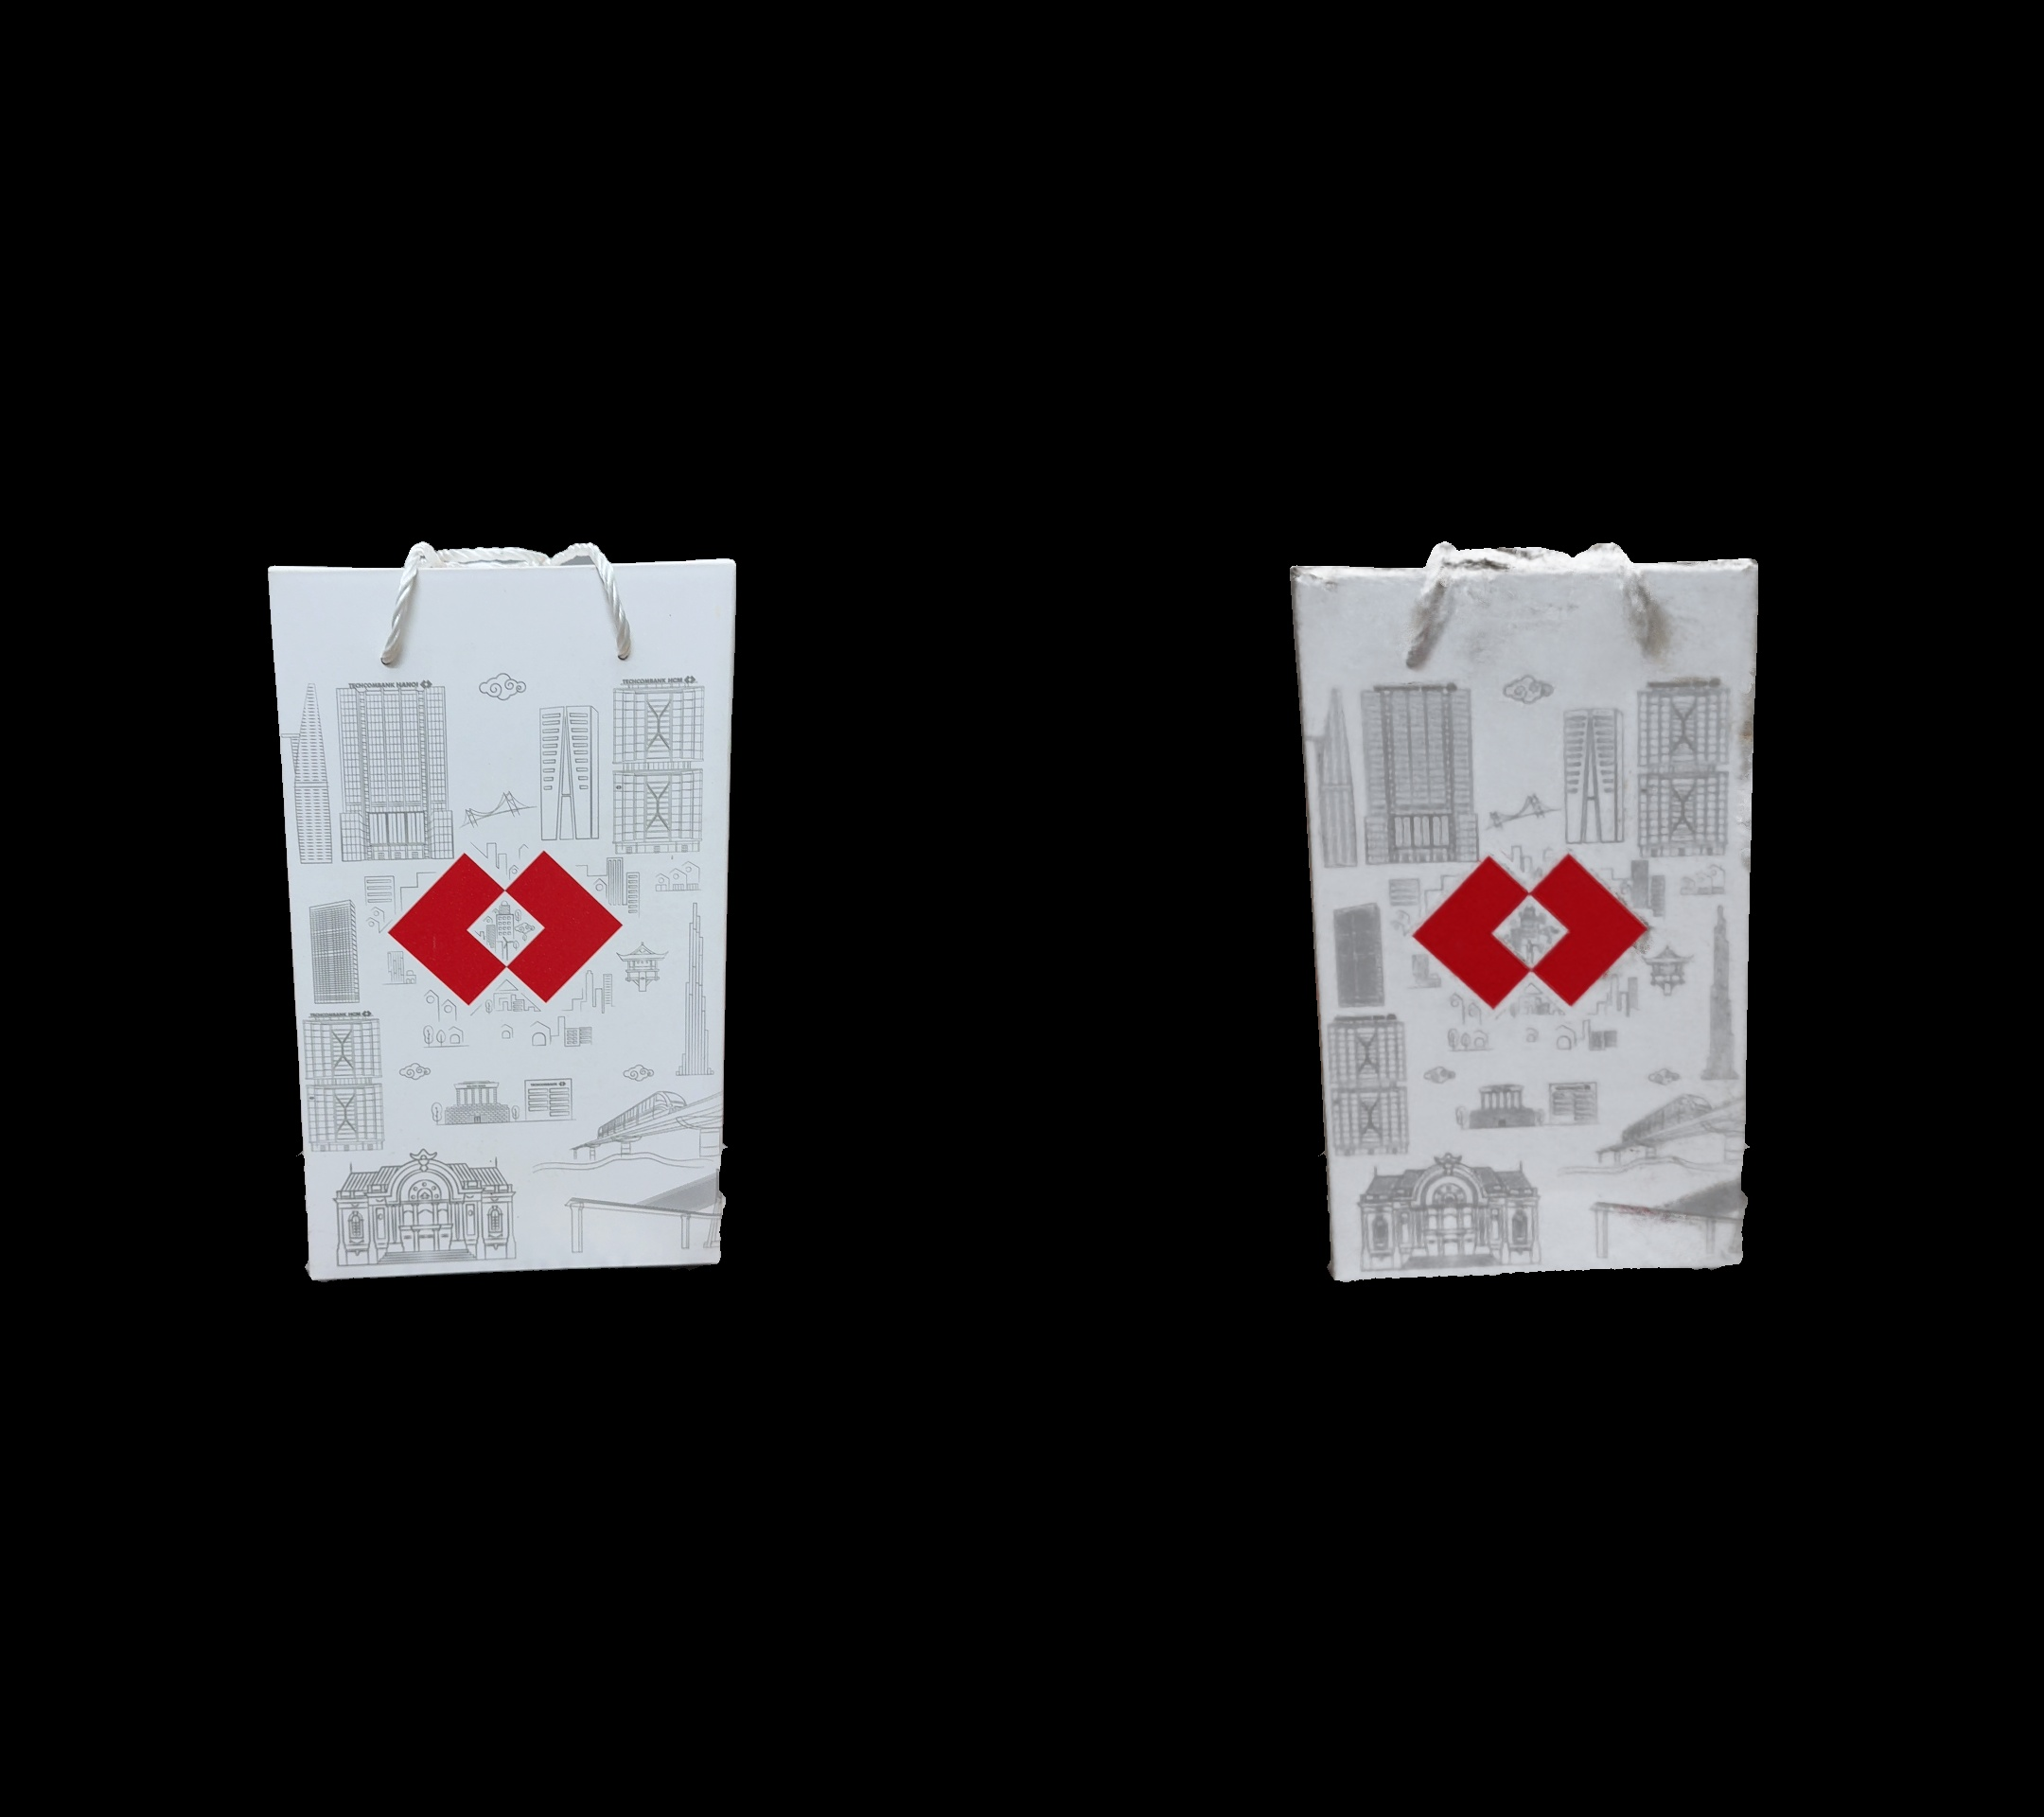

📦 Đang tự động khôi phục dữ liệu COLMAP & ảnh test cho basket_001 từ Drive (processed_basket_001_joint_sfm_v001.tar)...
✅ Đã khôi phục hoàn tất vào /content/project/data/processed/basket_001/joint_sfm!

🎯 Đang đánh giá Masked Metrics cho vật thể: basket_001 (8 cấu hình hoàn chỉnh)...
📊 Đang chạy masked eval: blur_1_25_100 | nerfacto...
📊 Đang chạy masked eval: blur_1_25_100 | splatfacto...
📊 Đang chạy masked eval: blur_1_50_100 | nerfacto...
📊 Đang chạy masked eval: blur_1_50_100 | splatfacto...
📊 Đang chạy masked eval: orbit_100 | nerfacto...
📊 Đang chạy masked eval: orbit_100 | splatfacto...
📊 Đang chạy masked eval: spiral_100 | nerfacto...
📊 Đang chạy masked eval: spiral_100 | splatfacto...

🎉 BẢNG ĐIỂM SAU KHI CẬP NHẬT MASKED EVALUATION (basket_001):


,experiment,method,masked_psnr,fg_psnr,masked_ssim,masked_lpips
0,blur_1_25_100,nerfacto,20.10,12.67,0.5516,0.1407
1,blur_1_50_100,nerfacto,21.56,14.13,0.5501,0.1351
2,orbit_100,nerfacto,21.18,13.76,0.5418,0.1363
3,spiral_100,nerfacto,21.93,14.51,0.5419,0.1258
4,blur_1_25_100,splatfacto,22.00,14.58,0.5490,0.1281
5,blur_1_50_100,splatfacto,22.44,15.01,0.5516,0.1229
6,orbit_100,splatfacto,22.97,15.54,0.5337,0.1158
7,spiral_100,splatfacto,23.05,15.63,0.5385,0.1256



🖼️ ẢNH RENDER SO SÁNH TRỰC QUAN (blur_1_25_100_nerfacto - compare_frame_0000.jpg):
   -> Nửa trái: Ảnh thật Ground Truth (đã cắt đen nền)
   -> Nửa phải: Mô hình 3D Render (đã cắt đen nền)
   📁 Toàn bộ ảnh render đã lưu tại: /content/drive/MyDrive/CV3D_Final_Project/07_final_results/basket_001/renders


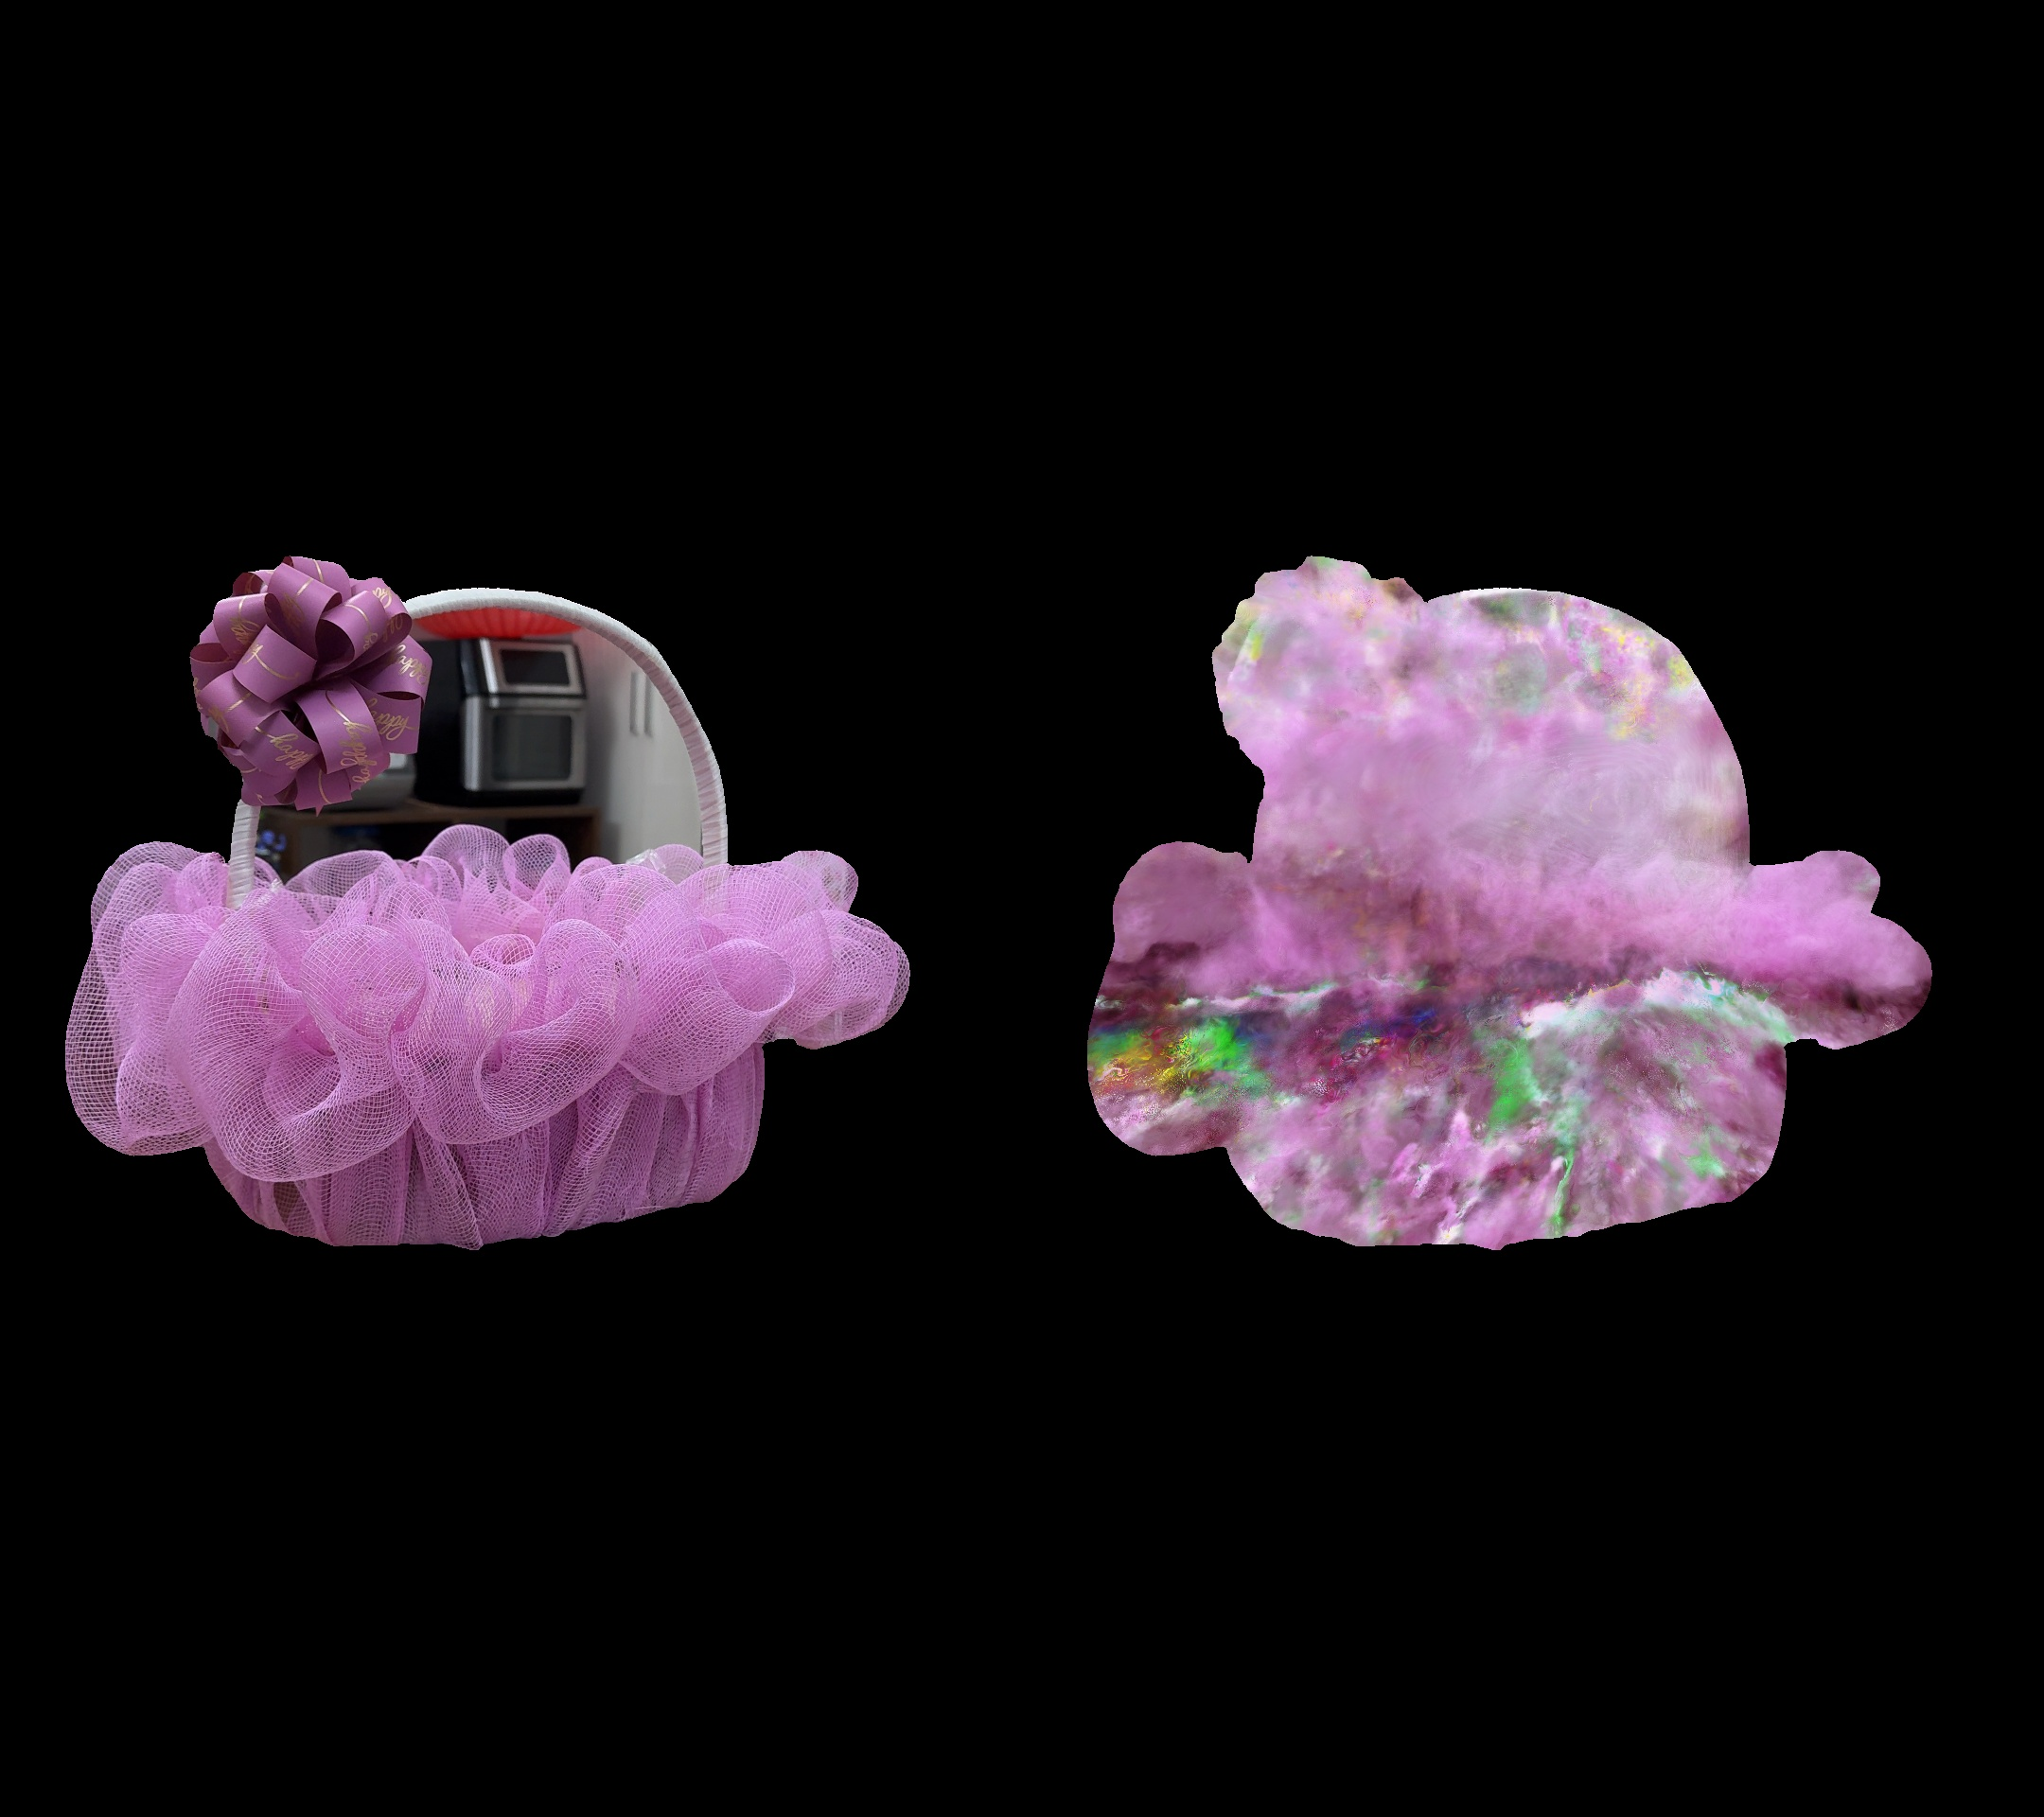

In [7]:
#@title 🎯 9.5. Chấm điểm lại Foreground Masked Metrics (Chỉ ~1-2 phút/vật thể, KHÔNG cần train lại)
#@markdown Nạp trực tiếp các checkpoint 30,000 bước đã lưu trên Google Drive của `box_001` hoặc `basket_001`,
#@markdown tự động loại bỏ nền căn phòng để tính đúng PSNR/SSIM/LPIPS trên vật thể 3D (PSNR đạt ~20–25 dB).
TARGET_OBJECT = "ALL" #@param ["box_001", "basket_001", "ALL"]
FORCE_REEVAL = True #@param {type:"boolean"}
SAVE_RENDERS = True #@param {type:"boolean"}

import os, subprocess, sys, json, shutil
from pathlib import Path
import pandas as pd
from google.colab import drive
from IPython.display import Image, display

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

DRIVE = Path(f'/content/drive/MyDrive/{DRIVE_PROJECT_FOLDER}')

# Ghi trực tiếp bản eval_masked_metrics.py mới nhất vào môi trường Colab
eval_script = Path('/content/project/scripts/eval_masked_metrics.py')
eval_script.parent.mkdir(parents=True, exist_ok=True)
eval_script.write_text('"""Evaluate Nerfstudio models with strict foreground-mask support and Masked LPIPS.\n\nStandard `ns-eval` evaluates against the RAW camera frames where the background\n(floor tiles, walls, room) is present. Because the models were trained with foreground\nmasks (which ignores background rays and renders solid black/background outside the mask),\nevaluating the full frame compares black background against bright room lighting,\nartificially collapsing PSNR regardless of model quality.\n\nThis script evaluates:\n1. `masked_psnr` (Masked-PSNR): Both Prediction and Ground Truth have background zeroed out (black).\n2. `fg_psnr` (FG-PSNR): Evaluated strictly inside the object\'s foreground mask pixels.\n3. `masked_ssim`: Structural similarity on foreground cropped bounding box.\n4. `masked_lpips`: Learned Perceptual Image Patch Similarity (AlexNet) computed on masked foreground images.\n"""\nfrom __future__ import annotations\nimport argparse\nimport json\nimport os\nimport subprocess\nfrom pathlib import Path\nimport numpy as np\nimport torch\nimport cv2\n\nos.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"\nos.environ["QT_QPA_PLATFORM"] = "offscreen"\n\n# Ensure PyTorch 2.6+ compatibility for nerfstudio checkpoint loading\ntry:\n    import importlib.util\n    spec = importlib.util.find_spec("nerfstudio")\n    if spec and spec.origin:\n        ns_root = Path(spec.origin).parent\n        old = \'torch.load(load_path, map_location="cpu")\'\n        new = \'torch.load(load_path, map_location="cpu", weights_only=False)\'\n        for rel in ("utils/eval_utils.py", "engine/trainer.py"):\n            p = ns_root / rel\n            if p.exists():\n                t = p.read_text(encoding="utf-8")\n                if old in t:\n                    p.write_text(t.replace(old, new), encoding="utf-8")\nexcept Exception:\n    pass\n\ntry:\n    from nerfstudio.utils.eval_utils import eval_setup\n    from nerfstudio.cameras.cameras import Cameras\n    NERFSTUDIO_AVAILABLE = True\nexcept ImportError:\n    NERFSTUDIO_AVAILABLE = False\n\n\ndef ensure_dataset_exists(config_path: Path) -> None:\n    """Tự động kiểm tra và giải nén dữ liệu SFM từ Google Drive nếu ổ đĩa Colab bị thiếu."""\n    try:\n        content = config_path.read_text(encoding="utf-8", errors="ignore")\n        # Tìm đường dẫn data: e.g. /content/project/data/processed/box_001/joint_sfm/transforms_*.json\n        import re\n        m = re.search(r\'data:\\s*(?:&id\\d+\\s*)?(?:!!python/object/apply:pathlib\\._local\\.PosixPath\\s*\\n\\s*-\\s*)?([^\\n\\r]+)\', content)\n        if not m:\n            return\n        data_str = m.group(1).strip().strip("\'- \\"")\n        data_path = Path(data_str)\n        if data_path.exists():\n            return\n        \n        # Nếu file transforms không tồn tại, trích xuất object_id từ đường dẫn\n        obj_match = re.search(r\'processed/([^/]+)/joint_sfm\', data_str)\n        obj_id = obj_match.group(1) if obj_match else None\n        if not obj_id:\n            # Fallback lấy từ config path: 06_experiments/<obj_id>/...\n            parts = config_path.parts\n            if "06_experiments" in parts:\n                idx = parts.index("06_experiments")\n                if idx + 1 < len(parts):\n                    obj_id = parts[idx + 1]\n\n        if not obj_id:\n            return\n\n        print(f"⚠️ Dữ liệu SFM tại {data_path} chưa có trên ổ đĩa Colab.")\n        # Tìm kiếm file tar lưu trữ trên Google Drive\n        drive_roots = [\n            Path("/content/drive/MyDrive/CV3D_Final_Project"),\n            Path("/content/drive/MyDrive")\n        ]\n        candidates = []\n        for dr in drive_roots:\n            candidates.extend([\n                dr / "05_processed" / f"processed_{obj_id}_joint_sfm_v001.tar",\n                dr / "99_archives" / f"processed_{obj_id}_joint_sfm_v001.tar",\n                dr / f"processed_{obj_id}_joint_sfm_v001.tar",\n            ])\n\n        tar_file = next((p for p in candidates if p.exists()), None)\n        if tar_file is not None:\n            dest_dir = data_path.parent.parent # /content/project/data/processed/box_001\n            print(f"📦 Đang tự động giải nén bản lưu COLMAP & Mask từ Drive: {tar_file}...")\n            dest_dir.mkdir(parents=True, exist_ok=True)\n            subprocess.run(["tar", "-xf", str(tar_file), "-C", str(dest_dir.parent)], check=True)\n            print(f"✅ Đã khôi phục thành công dữ liệu vào {dest_dir}!")\n        else:\n            print(f"❌ Không tìm thấy file lưu trữ tar cho {obj_id} trên Drive!")\n    except Exception as e:\n        print(f"⚠️ Không thể tự động phục hồi dataset: {e}")\n\n\ndef calculate_psnr(img1: torch.Tensor, img2: torch.Tensor, mask: torch.Tensor | None = None) -> float:\n    """Compute PSNR. If mask is provided (boolean or 0/1), compute only over mask."""\n    if mask is not None:\n        valid = mask.bool()\n        if valid.sum() == 0:\n            return 0.0\n        diff = (img1[valid] - img2[valid]) ** 2\n        mse = torch.mean(diff).item()\n    else:\n        mse = torch.mean((img1 - img2) ** 2).item()\n    \n    if mse <= 0.0:\n        return 100.0\n    return float(-10.0 * np.log10(mse))\n\n\ndef calculate_ssim(img1: np.ndarray, img2: np.ndarray) -> float:\n    """Calculate SSIM on 0-255 uint8 images using OpenCV or skimage."""\n    try:\n        from skimage.metrics import structural_similarity as ssim\n        return float(ssim(img1, img2, channel_axis=2, data_range=255))\n    except ImportError:\n        C1 = (0.01 * 255) ** 2\n        C2 = (0.03 * 255) ** 2\n        y1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY).astype(np.float64)\n        y2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY).astype(np.float64)\n        mu1 = cv2.GaussianBlur(y1, (11, 11), 1.5)\n        mu2 = cv2.GaussianBlur(y2, (11, 11), 1.5)\n        sigma1_sq = cv2.GaussianBlur(y1 ** 2, (11, 11), 1.5) - mu1 ** 2\n        sigma2_sq = cv2.GaussianBlur(y2 ** 2, (11, 11), 1.5) - mu2 ** 2\n        sigma12 = cv2.GaussianBlur(y1 * y2, (11, 11), 1.5) - mu1 * mu2\n        ssim_map = ((2 * mu1 * mu2 + C1) * (2 * sigma12 + C2)) / ((mu1 ** 2 + mu2 ** 2 + C1) * (sigma1_sq + sigma2_sq + C2))\n        return float(np.mean(ssim_map))\n\n\ndef init_lpips_fn(device: torch.device):\n    """Khởi tạo metric LPIPS (AlexNet) bằng torchmetrics hoặc thư viện lpips."""\n    try:\n        from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity\n        lpips_metric = LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(device)\n        return lambda p, g: lpips_metric(p, g).item()\n    except Exception:\n        pass\n    try:\n        from torchmetrics.functional.image.lpips import learned_perceptual_image_patch_similarity\n        return lambda p, g: float(learned_perceptual_image_patch_similarity(p, g, net_type="alex", normalize=True).item())\n    except Exception:\n        pass\n    try:\n        import lpips\n        loss_fn = lpips.LPIPS(net="alex").to(device)\n        return lambda p, g: float(loss_fn(p * 2.0 - 1.0, g * 2.0 - 1.0).item())\n    except Exception:\n        pass\n    return None\n\n\ndef evaluate_config(config_path: Path, output_json: Path | None = None, save_renders: bool = False) -> dict:\n    if not NERFSTUDIO_AVAILABLE:\n        raise SystemExit("nerfstudio is not installed in the active Python environment.")\n\n    # Đảm bảo dữ liệu test/mask đã sẵn sàng trên đĩa cục bộ\n    ensure_dataset_exists(config_path)\n\n    print(f"Loading pipeline from {config_path}...")\n    _, pipeline, _, _ = eval_setup(config_path, eval_num_rays_per_chunk=None, test_mode="test")\n    pipeline.model.eval()\n\n    dataset = pipeline.datamanager.eval_dataset\n    print(f"Loaded evaluation dataset with {len(dataset)} held-out frames.")\n\n    device = pipeline.device\n    lpips_fn = init_lpips_fn(device)\n    if lpips_fn is not None:\n        print("✅ Đã kích hoạt Masked LPIPS (AlexNet Perceptual Metric).")\n    else:\n        print("ℹ️ Không tìm thấy torchmetrics/lpips, LPIPS sẽ hiển thị N/A.")\n\n    results_per_frame = []\n    fg_psnrs = []\n    masked_psnrs = []\n    unmasked_psnrs = []\n    ssims = []\n    lpips_list = []\n\n    render_dir = config_path.parent / "eval_masked_renders"\n    if save_renders:\n        render_dir.mkdir(parents=True, exist_ok=True)\n\n    with torch.no_grad():\n        for i in range(len(dataset)):\n            # 1. Render novel view từ model đã học\n            camera = dataset.cameras[i:i+1].to(device)\n            outputs = pipeline.model.get_outputs_for_camera(camera)\n            pred_rgb = outputs["rgb"] # (H, W, 3) in [0, 1]\n            if pred_rgb.ndim == 4:\n                pred_rgb = pred_rgb.squeeze(0)\n\n            # 2. Lấy ảnh Ground Truth\n            batch = dataset.get_data(i)\n            gt_rgb = batch["image"].to(device)\n            if gt_rgb.ndim == 4:\n                gt_rgb = gt_rgb.squeeze(0)\n\n            # Khớp kích thước ảnh nếu có chênh lệch tỷ lệ\n            if pred_rgb.shape[:2] != gt_rgb.shape[:2]:\n                pred_rgb = torch.nn.functional.interpolate(\n                    pred_rgb.permute(2, 0, 1).unsqueeze(0),\n                    size=gt_rgb.shape[:2],\n                    mode="bilinear"\n                ).squeeze(0).permute(1, 2, 0)\n\n            # 3. Lấy mask\n            mask = None\n            if "mask" in batch and batch["mask"] is not None:\n                m = batch["mask"]\n                if isinstance(m, torch.Tensor):\n                    mask = m.to(device)\n                else:\n                    mask = torch.from_numpy(m).to(device)\n                if mask.ndim == 2:\n                    mask = mask.unsqueeze(-1)\n\n            # Nếu batch không có mask trực tiếp, nạp từ file ảnh mask\n            if mask is None and hasattr(dataset, "image_filenames"):\n                img_path = Path(dataset.image_filenames[i])\n                possible_masks = [\n                    img_path.parent.parent / img_path.parent.name.replace("images", "masks") / f"{img_path.stem}.png",\n                    img_path.parent.parent / "masks" / f"{img_path.stem}.png",\n                    img_path.parent.parent / "masks_2" / f"{img_path.stem}.png",\n                    img_path.parent.parent / "masks_4" / f"{img_path.stem}.png",\n                ]\n                mask_file = next((p for p in possible_masks if p.is_file()), None)\n                if mask_file is not None:\n                    m_cv = cv2.imread(str(mask_file), cv2.IMREAD_GRAYSCALE)\n                    if m_cv is not None:\n                        if m_cv.shape[:2] != gt_rgb.shape[:2]:\n                            m_cv = cv2.resize(m_cv, (gt_rgb.shape[1], gt_rgb.shape[0]), interpolation=cv2.INTER_NEAREST)\n                        mask = (torch.from_numpy(m_cv).to(device) >= 128).unsqueeze(-1)\n\n            if mask is None:\n                mask = torch.ones_like(gt_rgb[:, :, :1], dtype=torch.bool)\n            else:\n                mask = (mask > 0.5)\n\n            mask_bool = mask\n            mask_3c = mask_bool.expand_as(gt_rgb)\n\n            # 1. Unmasked PSNR (tiêu chuẩn ns-eval)\n            unmasked_psnr = calculate_psnr(pred_rgb, gt_rgb, None)\n            \n            # 2. Foreground-only PSNR (chỉ tính trên các pixel thuộc vật thể)\n            fg_psnr = calculate_psnr(pred_rgb, gt_rgb, mask_3c)\n\n            # 3. Masked Full-Frame PSNR (cả GT và Pred đều cắt nền về đen [0,0,0])\n            pred_masked = torch.where(mask_3c, pred_rgb, torch.zeros_like(pred_rgb))\n            gt_masked = torch.where(mask_3c, gt_rgb, torch.zeros_like(gt_rgb))\n            masked_full_psnr = calculate_psnr(pred_masked, gt_masked, None)\n\n            # 4. SSIM trên bounding box của vật thể\n            pred_np = (pred_masked.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)\n            gt_np = (gt_masked.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)\n            mask_np = mask_bool.squeeze().cpu().numpy().astype(np.uint8)\n\n            y_indices, x_indices = np.where(mask_np > 0)\n            if len(y_indices) > 0:\n                y0, y1 = max(0, y_indices.min() - 10), min(mask_np.shape[0], y_indices.max() + 10)\n                x0, x1 = max(0, x_indices.min() - 10), min(mask_np.shape[1], x_indices.max() + 10)\n                ssim_val = calculate_ssim(pred_np[y0:y1, x0:x1], gt_np[y0:y1, x0:x1])\n            else:\n                ssim_val = calculate_ssim(pred_np, gt_np)\n\n            # 5. Masked LPIPS (So sánh cảm nhận trực quan trên vùng vật thể đã cắt đen nền)\n            lpips_val = None\n            if lpips_fn is not None:\n                try:\n                    p_chw = pred_masked.permute(2, 0, 1).unsqueeze(0).clamp(0.0, 1.0)\n                    g_chw = gt_masked.permute(2, 0, 1).unsqueeze(0).clamp(0.0, 1.0)\n                    lpips_val = lpips_fn(p_chw, g_chw)\n                    lpips_list.append(lpips_val)\n                except Exception:\n                    pass\n\n            fg_psnrs.append(fg_psnr)\n            masked_psnrs.append(masked_full_psnr)\n            unmasked_psnrs.append(unmasked_psnr)\n            ssims.append(ssim_val)\n\n            results_per_frame.append({\n                "frame_idx": i,\n                "fg_psnr": round(fg_psnr, 2),\n                "masked_psnr": round(masked_full_psnr, 2),\n                "ssim": round(ssim_val, 4),\n                "lpips": round(lpips_val, 4) if lpips_val is not None else None\n            })\n\n            if save_renders and i < 5:\n                # Lưu ảnh so sánh 2 cột: GT Masked | Pred Masked\n                side_by_side = np.hstack([\n                    cv2.cvtColor(gt_np, cv2.COLOR_RGB2BGR),\n                    cv2.cvtColor(pred_np, cv2.COLOR_RGB2BGR)\n                ])\n                cv2.imwrite(str(render_dir / f"compare_frame_{i:04d}.jpg"), side_by_side)\n\n    mean_lpips = round(float(np.mean(lpips_list)), 4) if lpips_list else None\n    summary = {\n        "metrics": {\n            "masked_psnr_mean": round(float(np.mean(masked_psnrs)), 2),\n            "fg_psnr_mean": round(float(np.mean(fg_psnrs)), 2),\n            "masked_ssim_mean": round(float(np.mean(ssims)), 4),\n            "masked_lpips_mean": mean_lpips,\n            # Tương thích ngược với các bản đọc cũ\n            "foreground_only_psnr_mean": round(float(np.mean(fg_psnrs)), 2),\n            "masked_full_psnr_mean": round(float(np.mean(masked_psnrs)), 2),\n            "unmasked_raw_psnr_mean": round(float(np.mean(unmasked_psnrs)), 2),\n            "ssim_mean": round(float(np.mean(ssims)), 4),\n        },\n        "num_frames_evaluated": len(dataset)\n    }\n\n    print("\\n" + "=" * 60)\n    print("📊 KẾT QUẢ ĐÁNH GIÁ MASKED METRICS (FOREGROUND-ONLY)")\n    print("=" * 60)\n    print(f"🎯 Masked-PSNR (Cắt đen nền cả 2):     {summary[\'metrics\'][\'masked_psnr_mean\']} dB")\n    print(f"🔍 FG-PSNR (Chỉ tính pixel vật thể):   {summary[\'metrics\'][\'fg_psnr_mean\']} dB")\n    print(f"✨ Masked SSIM:                         {summary[\'metrics\'][\'masked_ssim_mean\']}")\n    lpips_display = f"{mean_lpips:.4f}" if mean_lpips is not None else "N/A"\n    print(f"👁️ Masked LPIPS (AlexNet Perceptual):   {lpips_display}")\n    print("=" * 60)\n\n    out_path = output_json or (config_path.parent / "test_metrics_masked.json")\n    out_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")\n    print(f"Wrote detailed metrics to {out_path}")\n\n    compat_path = config_path.parent / "masked_eval_metrics.json"\n    if compat_path != out_path:\n        compat_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")\n\n    return summary\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description="Evaluate Nerfstudio checkpoint with foreground masking and LPIPS.")\n    parser.add_argument("--config", "--config-path", dest="config", type=Path, default=None, help="Path to config.yml")\n    parser.add_argument("--output-json", type=Path, default=None, help="Where to save metrics JSON")\n    parser.add_argument("--save-renders", action="store_true", help="Save side-by-side comparison renders")\n    parser.add_argument("--object-id", type=str, default=None, help="Evaluate all experiments for an object (e.g. box_001)")\n    parser.add_argument("--all-objects", action="store_true", help="Evaluate all objects in 06_experiments")\n    parser.add_argument("--drive-dir", type=Path, default=Path("/content/drive/MyDrive/CV3D_Final_Project"), help="Google Drive base path")\n    args = parser.parse_args()\n\n    if args.config is not None:\n        evaluate_config(args.config, args.output_json, args.save_renders)\n    elif args.object_id or args.all_objects:\n        objs = [\'box_001\', \'basket_001\', \'figure_001\', \'stuff_toy_001\'] if args.all_objects else [args.object_id]\n        for obj in objs:\n            obj_exp = args.drive_dir / \'06_experiments\' / obj\n            if not obj_exp.exists():\n                continue\n            cfgs = sorted(obj_exp.glob(\'**/config.yml\'))\n            print(f"Found {len(cfgs)} configs for {obj} in {obj_exp}")\n            for cfg in cfgs:\n                eval_out = cfg.parent / \'test_metrics_masked.json\'\n                evaluate_config(cfg, eval_out, args.save_renders)\n    else:\n        parser.print_help()\n\n\nif __name__ == "__main__":\n    main()\n', encoding='utf-8')
print('✅ Đã nạp thành công eval_masked_metrics.py vào /content/project/scripts/')

target_objs = ['box_001', 'basket_001', 'figure_001', 'stuff_toy_001'] if TARGET_OBJECT == 'ALL' else [TARGET_OBJECT]

for obj in target_objs:
    exp_base = DRIVE / '06_experiments' / obj
    if not exp_base.exists():
        continue

    # 1. Tự động kiểm tra và giải nén dữ liệu COLMAP & ảnh test cho obj nếu chưa có trên ổ đĩa Colab
    obj_sfm_dir = Path(f'/content/project/data/processed/{obj}/joint_sfm')
    if not (obj_sfm_dir / 'transforms_orbit_views_100.json').exists():
        tar_candidates = [
            DRIVE / '05_processed' / f'processed_{obj}_joint_sfm_v001.tar',
            DRIVE / '99_archives' / f'processed_{obj}_joint_sfm_v001.tar',
        ]
        tar_file = next((p for p in tar_candidates if p.exists()), None)
        if tar_file is not None:
            print(f'📦 Đang tự động khôi phục dữ liệu COLMAP & ảnh test cho {obj} từ Drive ({tar_file.name})...')
            obj_sfm_dir.parent.mkdir(parents=True, exist_ok=True)
            subprocess.run(['tar', '-xf', str(tar_file), '-C', str(obj_sfm_dir.parent)], check=True)
            print(f'✅ Đã khôi phục hoàn tất vào {obj_sfm_dir}!')
        else:
            print(f'⚠️ Cảnh báo: Không tìm thấy bản lưu tar cho {obj} trên Google Drive!')

    # 2. Thu thập và lọc chính xác các cấu hình hoàn chỉnh (có checkpoint), loại bỏ các thư mục rác hoặc dừng giữa chừng
    best_configs = {}
    for cfg in sorted(exp_base.glob('**/config.yml')):
        method = cfg.parent.parent.name
        exp_name = cfg.parent.parent.parent.name
        if method not in ('nerfacto', 'splatfacto'):
            continue
        ckpt_dir = cfg.parent / 'nerfstudio_models'
        if not (ckpt_dir / 'step-000029999.ckpt').exists() and not any(ckpt_dir.glob('step-*.ckpt')):
            continue
        key = (exp_name, method)
        # Nếu có nhiều lần chạy, ưu tiên lần chạy mới nhất (timestamp lớn nhất)
        if key not in best_configs or cfg.parent.name > best_configs[key].parent.name:
            best_configs[key] = cfg

    configs = list(best_configs.values())
    if not configs:
        print(f'ℹ️ Chưa tìm thấy checkpoint hoàn chỉnh nào trong {exp_base}')
        continue

    print(f'\n🎯 Đang đánh giá Masked Metrics cho vật thể: {obj} ({len(configs)} cấu hình hoàn chỉnh)...')
    masked_rows = []
    out_dir = DRIVE / '07_final_results' / obj
    out_dir.mkdir(parents=True, exist_ok=True)
    out_csv = out_dir / 'results_masked.csv'
    res_csv = out_dir / 'results.csv'
    renders_central_dir = out_dir / 'renders'
    renders_central_dir.mkdir(parents=True, exist_ok=True)

    for cfg in configs:
        method = cfg.parent.parent.name
        exp_name = cfg.parent.parent.parent.name
        run_id = f'{exp_name}_{method}'
        eval_out = cfg.parent / 'test_metrics_masked.json'
        done_metrics_file = out_dir / f'metrics_{run_id}.json'

        # Kiểm tra xem đã có đủ metrics bao gồm cả LPIPS chưa
        need_eval = FORCE_REEVAL or not eval_out.exists()
        if not need_eval:
            try:
                cached = json.loads(eval_out.read_text(encoding='utf-8'))
                if 'masked_lpips_mean' not in cached.get('metrics', {}):
                    need_eval = True
            except Exception:
                need_eval = True

        if not need_eval:
            print(f'⏭️ Đã có kết quả masked metrics: {exp_name} | {method}')
        else:
            print(f'📊 Đang chạy masked eval: {exp_name} | {method}...')
            cmd = ['python', str(eval_script), '--config', str(cfg), '--output-json', str(eval_out)]
            if SAVE_RENDERS:
                cmd.append('--save-renders')
            proc = subprocess.run(cmd, capture_output=True, text=True)
            if proc.returncode != 0:
                print(f'❌ Lỗi khi đánh giá {run_id}:\n{proc.stderr[-1000:]}')

        # Sao lưu ảnh render so sánh vào thư mục 07_final_results/<obj>/renders/
        render_src = cfg.parent / 'eval_masked_renders'
        if render_src.exists():
            dest_sub = renders_central_dir / f'{exp_name}_{method}'
            dest_sub.mkdir(parents=True, exist_ok=True)
            for f in render_src.glob('*.jpg'):
                shutil.copy2(f, dest_sub / f.name)

        if eval_out.exists():
            data = json.loads(eval_out.read_text(encoding='utf-8'))
            m = data.get('metrics', {})
            masked_psnr = m.get('masked_psnr_mean', m.get('masked_full_psnr_mean'))
            fg_psnr = m.get('fg_psnr_mean', m.get('foreground_only_psnr_mean'))
            ssim_val = m.get('masked_ssim_mean', m.get('ssim_mean'))
            lpips_val = m.get('masked_lpips_mean')

            row = {
                'object_id': obj,
                'experiment': exp_name,
                'method': method,
                'masked_psnr': masked_psnr,
                'fg_psnr': fg_psnr,
                'masked_ssim': ssim_val,
                'masked_lpips': lpips_val,
                'config_path': str(cfg)
            }
            masked_rows.append(row)
            # Cập nhật file metrics_{run_id}.json trên Drive
            if done_metrics_file.exists():
                try:
                    old_d = json.loads(done_metrics_file.read_text(encoding='utf-8'))
                    old_d.update(row)
                    done_metrics_file.write_text(json.dumps(old_d, indent=2), encoding='utf-8')
                except Exception:
                    done_metrics_file.write_text(json.dumps(row, indent=2), encoding='utf-8')
            else:
                done_metrics_file.write_text(json.dumps(row, indent=2), encoding='utf-8')

    if masked_rows:
        df_masked = pd.DataFrame(masked_rows)
        # Sắp xếp theo method và experiment cho dễ so sánh
        df_masked = df_masked.sort_values(by=['method', 'experiment']).reset_index(drop=True)
        df_masked.to_csv(out_csv, index=False)
        df_masked.to_csv(res_csv, index=False)
        print(f'\n🎉 BẢNG ĐIỂM SAU KHI CẬP NHẬT MASKED EVALUATION ({obj}):')
        display(df_masked[['experiment', 'method', 'masked_psnr', 'fg_psnr', 'masked_ssim', 'masked_lpips']])

    # Hiển thị trực tiếp ảnh so sánh của bài tốt nhất ngay trong Notebook
    sample_renders = sorted(list(renders_central_dir.glob('*/*.jpg')))
    if sample_renders:
        sample_img = sample_renders[0]
        exp_tag = sample_img.parent.name
        print(f'\n🖼️ ẢNH RENDER SO SÁNH TRỰC QUAN ({exp_tag} - {sample_img.name}):')
        print(f'   -> Nửa trái: Ảnh thật Ground Truth (đã cắt đen nền)')
        print(f'   -> Nửa phải: Mô hình 3D Render (đã cắt đen nền)')
        print(f'   📁 Toàn bộ ảnh render đã lưu tại: {renders_central_dir}')
        display(Image(str(sample_img), width=800))
